In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from eval.data import load_and_split
from medal.model import AutoEncoder
from medal.normalizer import GlobalEmbeddingNormalizer
import torch
import matplotlib.colors as mcolors
from pathlib import Path
import matplotlib.ticker as ticker
from sklearn.model_selection import train_test_split
from utils import compute_param_choice, build_figure, build_distortion_figure
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import ConnectionPatch
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import os
PATH_PREFIX = os.environ.get('MEDAL_DATA_DIR', os.path.expanduser('~'))
%load_ext autoreload
%autoreload 2

/home/bnc2119/.conda/envs/medal/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-04-27 00:47:58,148	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-04-27 00:48:08,218	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:
# loading AE
def load_trained_ae(ckpt_path, input_dim, hidden_dims,activation=torch.nn.SELU, latent_dim=2, batchnorm=False):
    import sys, os
    old_stdout = sys.stdout
    sys.stdout = open(os.devnull, "w")
    model = AutoEncoder(
        input_dim=input_dim,
        latent_dim=latent_dim,
        hidden_dims=hidden_dims,
        activation=activation,            
        bottleneck_activation=None,
        use_batchnorm = batchnorm
    )
    sys.stdout = old_stdout

    sd = torch.load(ckpt_path, map_location="cpu")
    if isinstance(sd, dict) and "model" in sd and isinstance(sd["model"], dict):
        sd = sd["model"]
    elif isinstance(sd, dict) and "state_dict" in sd and isinstance(sd["state_dict"], dict):
        sd = sd["state_dict"]

    sd = {k.replace("module.", ""): v for k, v in sd.items()}
    missing, unexpected = model.load_state_dict(sd, strict=False)
    print(f"loaded params: {len(sd)} | missing={len(missing)} | unexpected={len(unexpected)}")
    if missing or unexpected:
        print("⚠️ Check architecture/keys. Example missing:", missing[:3], "unexpected:", unexpected[:3])

    model.eval()
    return model

def split_scdeed_labels(df, best_param):
    result = []
    for l in ["dubious", "trustworthy", "intermediate"]:
        vec = df.loc[best_param, f"{l}_cells"]
        ls_indices = np.array(vec.split(',')).astype(int)
        result.extend(list(zip([l]* len(ls_indices), ls_indices)))
    return pd.DataFrame(result, columns = ['label', 'index']).set_index('index').sort_index()

In [3]:
X_og, X_test, y_og, y_test = load_and_split("mnist", test_size=0.2, seed=0, labels=True)
X, X_val, y, y_val = train_test_split(X_og, y_og, test_size=0.2, random_state=0)
digit_palette = {
    '0': (0.122, 0.467, 0.706, 1.0),   # dark blue
    '1': (0.682, 0.780, 0.910, 1.0),   # light blue
    '2': (1.0,   0.498, 0.055, 1.0),   # dark orange
    '3': (1.0,   0.733, 0.471, 1.0),   # light orange
    '4': (0.173, 0.627, 0.173, 1.0),   # dark green
    '5': (0.596, 0.875, 0.541, 1.0),   # light green
    '6': (0.839, 0.153, 0.157, 1.0),   # dark red
    '7': (1.0,   0.596, 0.588, 1.0),   # light pink/red
    '8': (0.580, 0.404, 0.741, 1.0),   # dark purple
    '9': (0.773, 0.690, 0.835, 1.0),   # light purple
}
mnist_palette = {str(d): digit_palette[str(d)] for d in range(10)}
cmap = sns.color_palette("BuGn", as_cmap=True)

## Hyperparameter Tuning

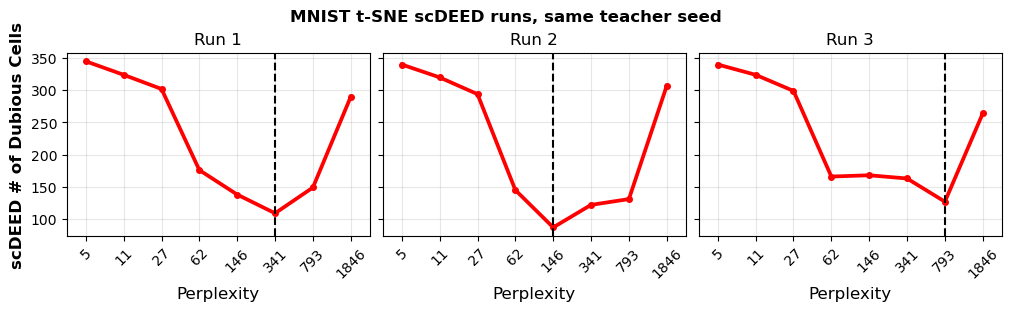

In [109]:
# showing that scdeed is inconsistent
methods = ['scdeed_1', 'scdeed_2', 'scdeed_3']
scdeed_1_best, scdeed_2_best, scdeed_3_best = 5, 5, 5
teacher_embed = {}
teacher_embed['scdeed_1'] = np.load(Path(PATH_PREFIX) / f"MEDAL/comparisons/data/mnist_train_umap_{scdeed_1_best}_0.1_0_train_pc6.npy")
teacher_embed['scdeed_2'] = np.load(Path(PATH_PREFIX) / f"MEDAL/comparisons/data/mnist_train_umap_{scdeed_2_best}_0.1_0_train_pc6.npy")
teacher_embed['scdeed_3'] = np.load(Path(PATH_PREFIX) / f"MEDAL/comparisons/data/mnist_train_umap_{scdeed_3_best}_0.1_0_train_pc6.npy")

scdeed_df1 = pd.read_csv(Path(PATH_PREFIX) / "MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_mnist_train_full_results.csv", index_col=0)
per_sample_scdeed1 = split_scdeed_labels(scdeed_df1, scdeed_1_best)['label']
scdeed_df2 = pd.read_csv(Path(PATH_PREFIX) / "MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_mnist_train_2_full_results.csv", index_col=0)
per_sample_scdeed2 = split_scdeed_labels(scdeed_df2, scdeed_2_best)['label']
scdeed_df3 = pd.read_csv(Path(PATH_PREFIX) / "MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_mnist_train_3_full_results.csv", index_col=0)
per_sample_scdeed3 = split_scdeed_labels(scdeed_df3, scdeed_3_best)['label']
palette_scdeed = {'dubious': 'red', 'intermediate': '#e8e8e8', 'trustworthy': "#9cc99f"}

scdeed_analysis1 = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_mnist_train_num_dubious.csv')
tsne_argmin = scdeed_analysis1['number_dubious_cells'].idxmin()
argmin_position1 = scdeed_analysis1.index.tolist().index(tsne_argmin)
scdeed_analysis2 = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_mnist_train_2_num_dubious.csv')
tsne_argmin = scdeed_analysis2['number_dubious_cells'].idxmin()
argmin_position2 = scdeed_analysis2.index.tolist().index(tsne_argmin)
scdeed_analysis3 = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_mnist_train_3_num_dubious.csv')
tsne_argmin = scdeed_analysis3['number_dubious_cells'].idxmin()
argmin_position3 = scdeed_analysis3.index.tolist().index(tsne_argmin)

cmap = sns.color_palette("BuGn", as_cmap=True)
fig, axes = plt.subplots(1,3, figsize=(10, 3), constrained_layout=True, sharey = 'row')
axes_flat = axes.flatten()

sns.pointplot(data=scdeed_analysis1, x='perplexity', y='number_dubious_cells', color='red', markersize=3, ax = axes_flat[0])
axes_flat[0].axvline(x = argmin_position1, ls = '--', c ='black')
axes_flat[0].set_title("Run 1")

sns.pointplot(data=scdeed_analysis2, x='perplexity', y='number_dubious_cells', color='red', markersize=3, ax = axes_flat[1])
axes_flat[1].axvline(x = argmin_position2, ls = '--', c ='black')
axes_flat[1].set_title("Run 2")

sns.pointplot(data=scdeed_analysis3, x='perplexity', y='number_dubious_cells', color='red', markersize=3, ax = axes_flat[2])
axes_flat[2].axvline(x = argmin_position3, ls = '--', c ='black')
axes_flat[2].set_title("Run 3")
axes_flat[0].set_ylabel("scDEED # of Dubious Cells", fontsize=12, fontweight='bold')

for i in [0,1,2]:
    axes_flat[i].grid(True, alpha=0.3)
    axes_flat[i].set_xlabel("Perplexity", fontsize=12)
    plt.setp(axes_flat[i].get_xticklabels(), rotation=45, ha='center')
    
fig.suptitle("MNIST t-SNE scDEED runs, same teacher seed", fontweight='bold')
plt.show()

In [4]:
mnist_pca_res_dict = []
for s in range(5):
    student_pca = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/mnist/medal_pca2_tc0_{s}_ckpts/final.pt",
            input_dim=784,
            hidden_dims=[512,512,512,512],
            latent_dim=2, batchnorm=False)
    
    student_recon, student_embed = student_pca(torch.tensor(X, dtype=torch.float32))
    train_recon = np.mean((student_recon.detach().numpy() - X)**2)
    mnist_pca_res_dict.append({"recon_loss": train_recon, "split": "Train", "seed": s})
    
    x_val_recon, _ = student_pca(torch.tensor(X_val, dtype=torch.float32))
    val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
    mnist_pca_res_dict.append({"recon_loss": val_recon, "split": "Val", "seed": s})

    x_test_recon, _ = student_pca(torch.tensor(X_test, dtype=torch.float32))
    test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
    mnist_pca_res_dict.append({"recon_loss": test_recon, "split": "Test", "seed": s})

/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0


/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded par

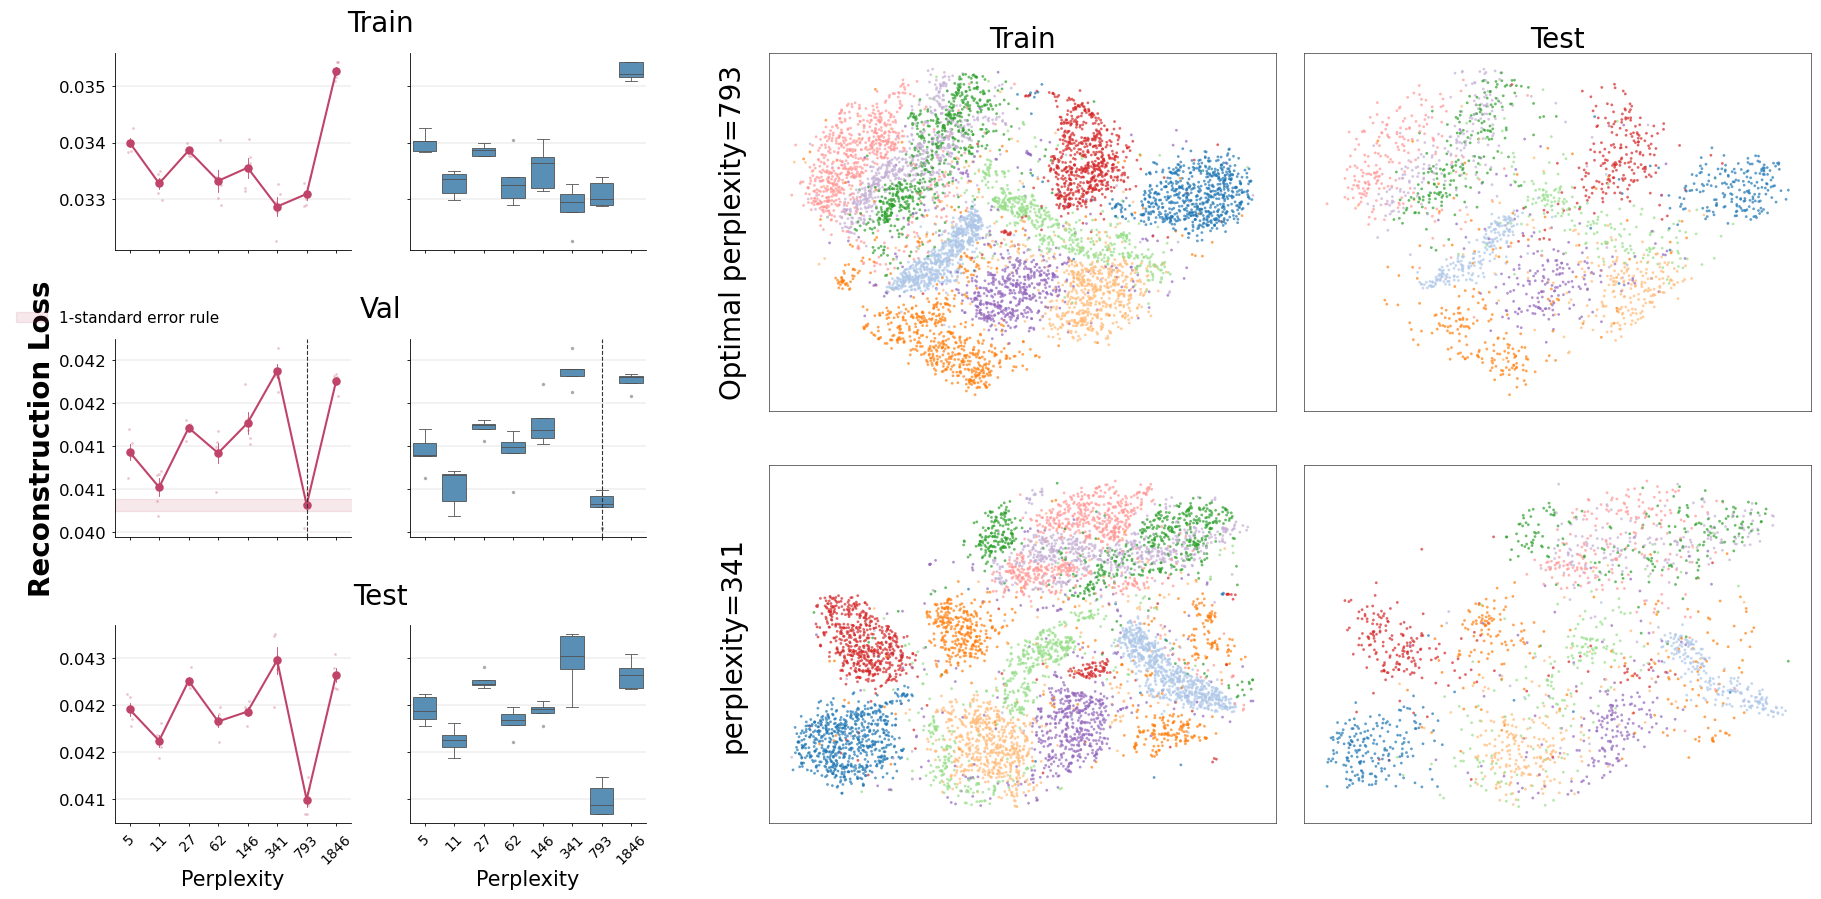

In [33]:
list_tsne_param = [793, 341]
student_tsne01 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/mnist/medal_tsne2_{list_tsne_param[0]}_tc0_0_ckpts/final.pt',
                input_dim=784,
                hidden_dims=[512,512,512,512],
                latent_dim=2, batchnorm=False)
student_recon_tsne01, student_embed_tsne01 = student_tsne01(torch.tensor(X, dtype=torch.float32))
student_recon_val_tsne01, student_embed_val_tsne01 = student_tsne01(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_tsne01, student_embed_test_tsne01 = student_tsne01(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_tsne01 = np.mean((student_recon_tsne01.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_tsne01 = np.mean((student_recon_val_tsne01.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_tsne01 = np.mean((student_recon_test_tsne01.detach().numpy() - X_test)**2, axis=1)

student_tsne02 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/mnist/medal_tsne2_{list_tsne_param[1]}_tc0_0_ckpts/final.pt',
                input_dim=784,
                hidden_dims=[512,512,512,512],
                latent_dim=2, batchnorm=False)
student_recon_tsne02, student_embed_tsne02 = student_tsne02(torch.tensor(X, dtype=torch.float32))
student_recon_val_tsne02, student_embed_val_tsne02 = student_tsne02(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_tsne02, student_embed_test_tsne02 = student_tsne02(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_tsne02 = np.mean((student_recon_tsne02.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_tsne02 = np.mean((student_recon_val_tsne02.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_tsne02 = np.mean((student_recon_test_tsne02.detach().numpy() - X_test)**2, axis=1)

# ── Build mnist_tsne_res_dict ───────────────────────────────────────────────────────────
mnist_tsne_res_dict = []
for s in range(5):
    for perp in [    5,    11,    27,    62,   146,   341,   793,  1846]:
        teacher_embed_raw = np.load(
            Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_tsne_{perp}_0_train.npy"
        )
        norm = GlobalEmbeddingNormalizer.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_tsne_{perp}_0_train.norm.pkl")
        teacher_embed = norm.transform(teacher_embed_raw)
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/mnist/medal_tsne2_{perp}_tc0_{s}_ckpts/final.pt",
                input_dim=784,
                hidden_dims=[512, 512, 512, 512],
                latent_dim=2, activation=torch.nn.SELU, batchnorm=False)

        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)
        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            mnist_tsne_res_dict.append({"perplexity": perp, "recon_loss": train_recon, "split": "Train", "seed": s})

            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            mnist_tsne_res_dict.append({"perplexity": perp, "recon_loss": val_recon, "split": "Val", "seed": s})

            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            mnist_tsne_res_dict.append({"perplexity": perp, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {perp} seed {s} due to distillation loss {train_distill}")

analysis, tsne_one_std_range, tsne_one_std_param_choice, unique_perplexities, vline_x = \
    compute_param_choice(mnist_tsne_res_dict, 'perplexity')

emb_data = {
    tsne_one_std_param_choice: {
        'Train': (student_embed_tsne01,      per_sample_recon_tsne01,      y),
        'Val':   (student_embed_val_tsne01,  per_sample_recon_val_tsne01,  y_val),
        'Test':  (student_embed_test_tsne01, per_sample_recon_test_tsne01, y_test),
    },
    list_tsne_param[1]: {
        'Train': (student_embed_tsne02,      per_sample_recon_tsne02,      y),
        'Val':   (student_embed_val_tsne02,  per_sample_recon_val_tsne02,  y_val),
        'Test':  (student_embed_test_tsne02, per_sample_recon_test_tsne02, y_test),
    },
}

build_figure(
    analysis, 'perplexity', unique_perplexities, tsne_one_std_range, vline_x,
    emb_data, [tsne_one_std_param_choice, 341], tsne_one_std_param_choice,
    mnist_palette, 'perplexity', 'Perplexity',
    row_label_y=1.15,
    legend_kw={'frameon': False, 'fontsize': 11, 'loc': 'lower right', 'bbox_to_anchor': (0.5, 1)},
    xtick_fontsize=10, figsize=(22, 10),
)

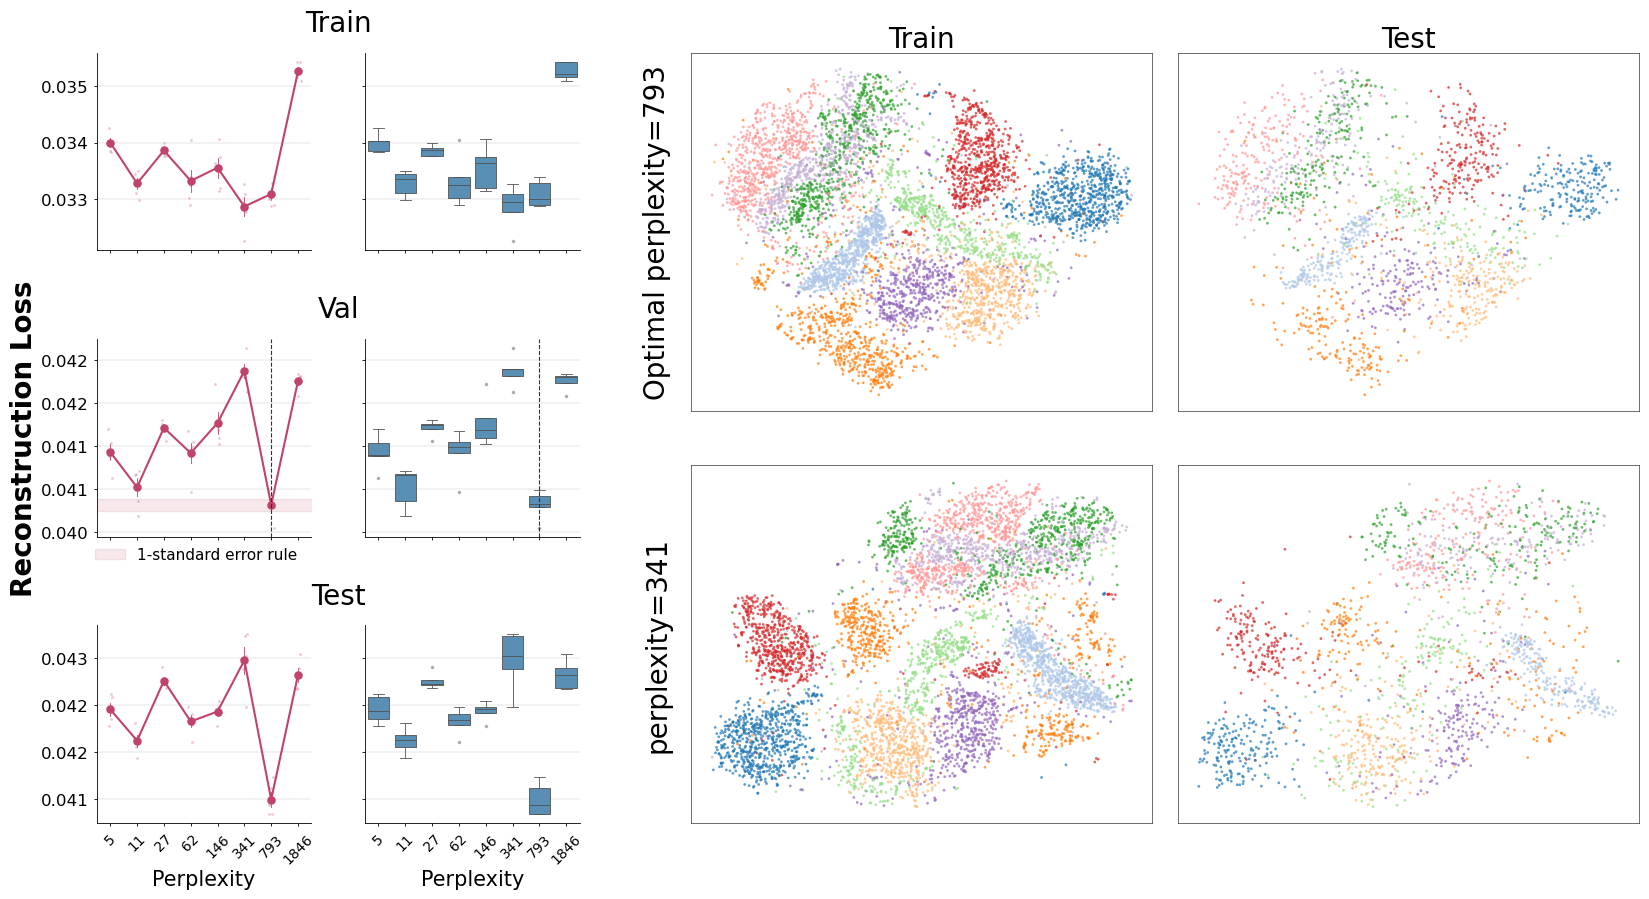

In [39]:
build_figure(
    analysis, 'perplexity', unique_perplexities, tsne_one_std_range, vline_x,
    emb_data, [tsne_one_std_param_choice, 341], tsne_one_std_param_choice,
    mnist_palette, 'perplexity', 'Perplexity',
    row_label_y=1.15,
    legend_kw={'frameon': False, 'fontsize': 11, 'loc': 'lower right', 'bbox_to_anchor': (1, -0.2)},
    xtick_fontsize=10, figsize=(20, 10),
)

In [28]:
mnist_umap_res_dict = []
for s in range(5):
    for n in np.unique(np.logspace(np.log10(5), np.log10(500), 15).astype(int)):
        teacher_embed_raw = np.load(
            Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_umap_{n}_0.1_0_train.npy"
        )
        norm = GlobalEmbeddingNormalizer.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_umap_{n}_0.1_0_train.norm.pkl")
        teacher_embed = norm.transform(teacher_embed_raw)
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/mnist/medal_umap2_{n}_0.1_tc0_{s}_ckpts/final.pt",
                input_dim=784,
                hidden_dims=[512, 512, 512, 512],
                latent_dim=2, activation=torch.nn.SELU, batchnorm=False)

        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)
        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            mnist_umap_res_dict.append({"n_neighbors": n, "recon_loss": train_recon, "split": "Train", "seed": s})

            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            mnist_umap_res_dict.append({"n_neighbors": n, "recon_loss": val_recon, "split": "Val", "seed": s})

            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            mnist_umap_res_dict.append({"n_neighbors": n, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {n} seed {s} due to distillation loss {train_distill}")

# ── Compute parameter choice ────────────────────────────────────────────────────────────────────────────────
analysis, umap_one_std_range, umap_one_std_param_choice, unique_neighbors, vline_x = \
    compute_param_choice(mnist_umap_res_dict, 'n_neighbors')

/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded par

In [12]:
list_umap_param = [umap_one_std_param_choice, 6]
student_umap01 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/mnist/medal_umap2_{list_umap_param[0]}_0.1_tc0_0_ckpts/final.pt',
                input_dim=784,
                hidden_dims=[512,512,512, 512],
                latent_dim=2, batchnorm=False)
student_recon_umap01, student_embed_umap01 = student_umap01(torch.tensor(X, dtype=torch.float32))
student_recon_val_umap01, student_embed_val_umap01 = student_umap01(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_umap01, student_embed_test_umap01 = student_umap01(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_umap01 = np.mean((student_recon_umap01.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_umap01 = np.mean((student_recon_val_umap01.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_umap01 = np.mean((student_recon_test_umap01.detach().numpy() - X_test)**2, axis=1)

student_umap02 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/mnist/medal_umap2_{list_umap_param[1]}_0.1_tc0_0_ckpts/final.pt',
                input_dim=784,
                hidden_dims=[512,512,512, 512],
                latent_dim=2, batchnorm=False)
student_recon_umap02, student_embed_umap02 = student_umap02(torch.tensor(X, dtype=torch.float32))
student_recon_val_umap02, student_embed_val_umap02 = student_umap02(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_umap02, student_embed_test_umap02 = student_umap02(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_umap02 = np.mean((student_recon_umap02.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_umap02 = np.mean((student_recon_val_umap02.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_umap02 = np.mean((student_recon_test_umap02.detach().numpy() - X_test)**2, axis=1)

# ── Figure ──────────────────────────────────────────────────────────────────────────────────────────────────────────
emb_data = {
    list_umap_param[0]: {
        'Train': (student_embed_umap01,      per_sample_recon_umap01,      y),
        'Val':   (student_embed_val_umap01,  per_sample_recon_val_umap01,  y_val),
        'Test':  (student_embed_test_umap01, per_sample_recon_test_umap01, y_test),
    },
    list_umap_param[1]: {
        'Train': (student_embed_umap02,      per_sample_recon_umap02,      y),
        'Val':   (student_embed_val_umap02,  per_sample_recon_val_umap02,  y_val),
        'Test':  (student_embed_test_umap02, per_sample_recon_test_umap02, y_test),
    },
}

/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0


/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0


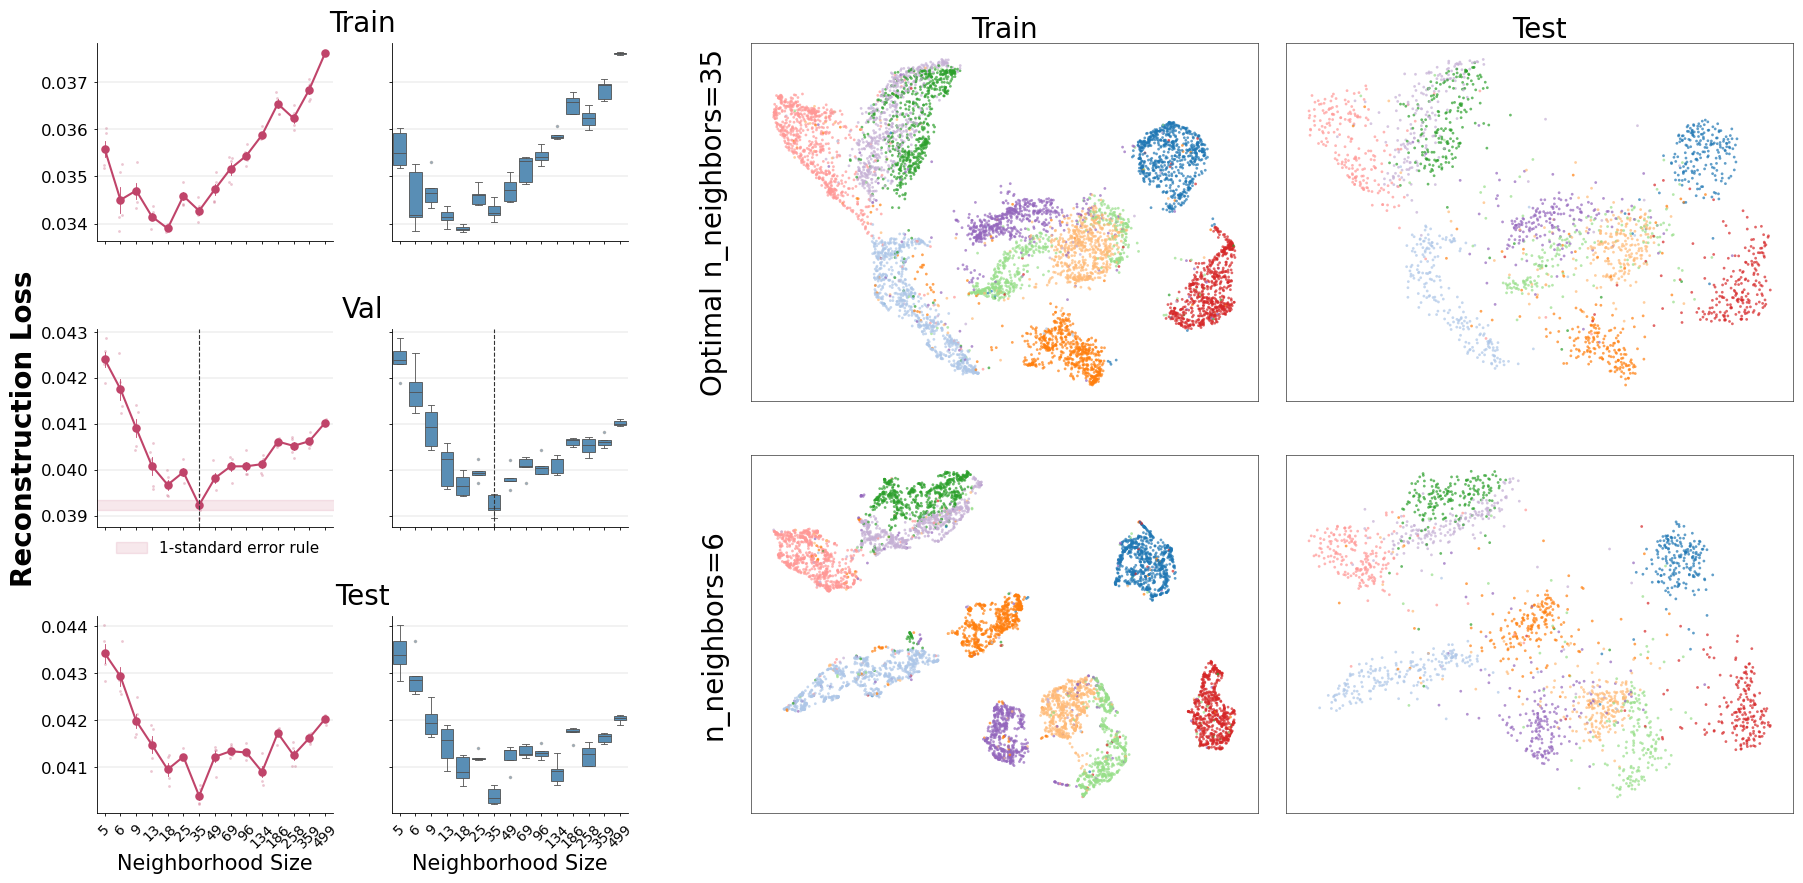

In [10]:
build_figure(
    analysis, 'n_neighbors', unique_neighbors, umap_one_std_range, vline_x,
    emb_data, list_umap_param, umap_one_std_param_choice,
    mnist_palette, 'n_neighbors', 'Neighborhood Size',
    row_label_y=1.1,
    legend_kw={'frameon': False, 'fontsize': 11, 'loc': 'best', 'bbox_to_anchor': (1, 0)},
    xtick_fontsize=10, figsize=(22, 10)
)

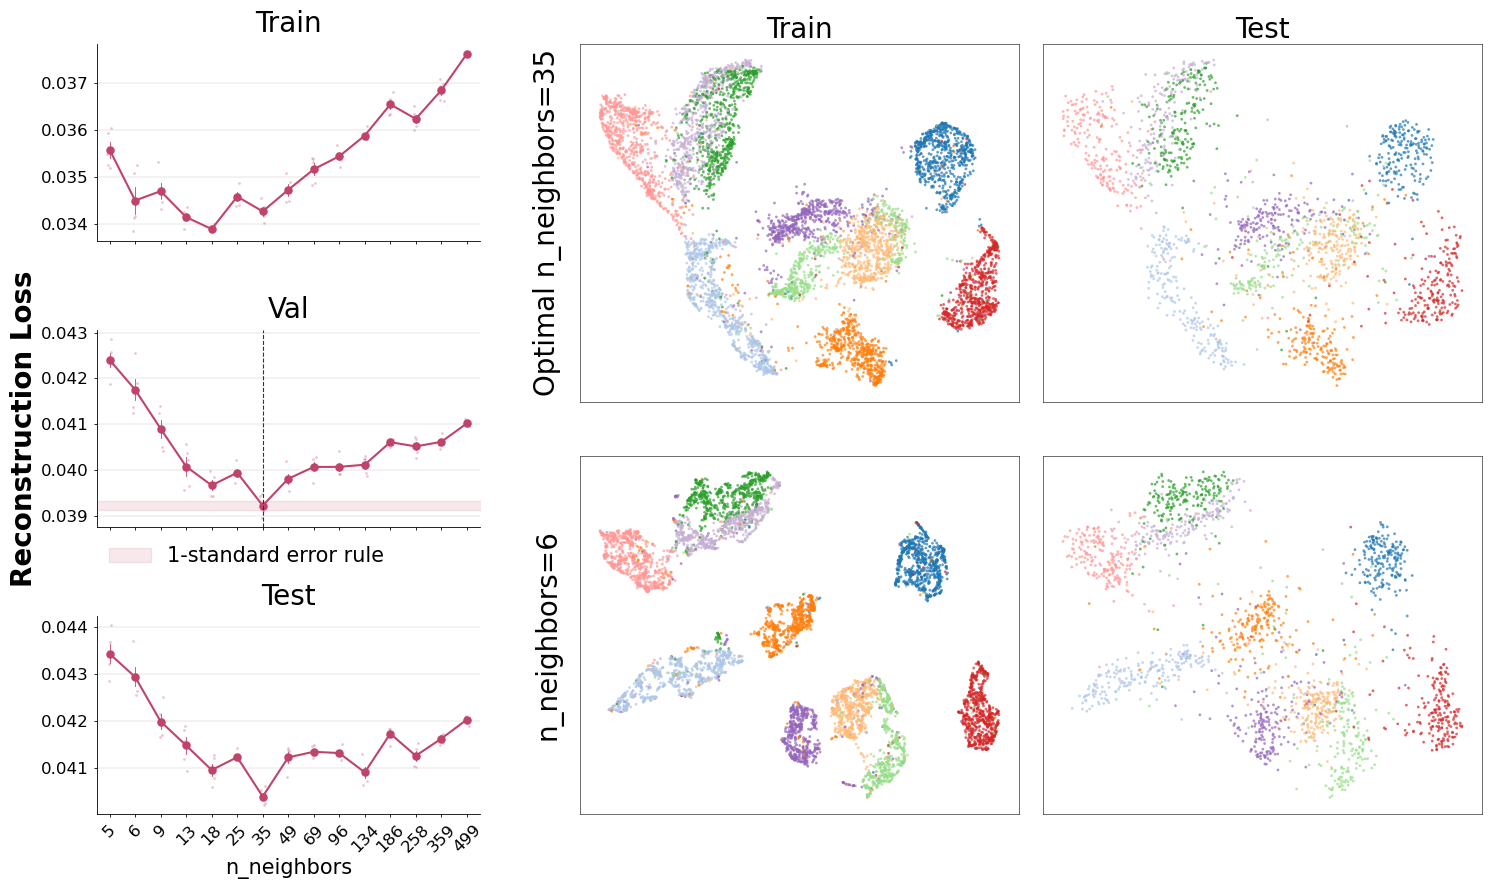

In [34]:
analysis, umap_one_std_range, umap_one_std_param_choice, unique_neighbors, vline_x = \
    compute_param_choice(mnist_umap_res_dict, 'n_neighbors')

emb_data = {
    list_umap_param[0]: {
        'Train': (student_embed_umap01,      per_sample_recon_umap01,      y),
#         'Val':   (student_embed_val_umap01,  per_sample_recon_val_umap01,  y_val),
        'Test':  (student_embed_test_umap01, per_sample_recon_test_umap01, y_test),
    },
    list_umap_param[1]: {
        'Train': (student_embed_umap02,      per_sample_recon_umap02,      y),
#         'Val':   (student_embed_val_umap02,  per_sample_recon_val_umap02,  y_val),
        'Test':  (student_embed_test_umap02, per_sample_recon_test_umap02, y_test),
    },
}

build_figure(
    analysis, 'n_neighbors', unique_neighbors, umap_one_std_range, vline_x,
    emb_data, list_umap_param, umap_one_std_param_choice,
    mnist_palette, 'n_neighbors', 'n_neighbors',
    row_label_y=1.1, figsize=(18, 10),
    legend_kw={'frameon': False, 'fontsize': 15, 'loc': 'best', 'bbox_to_anchor': (0.8, 0)},
    xtick_fontsize=12,show_boxplot=False
)

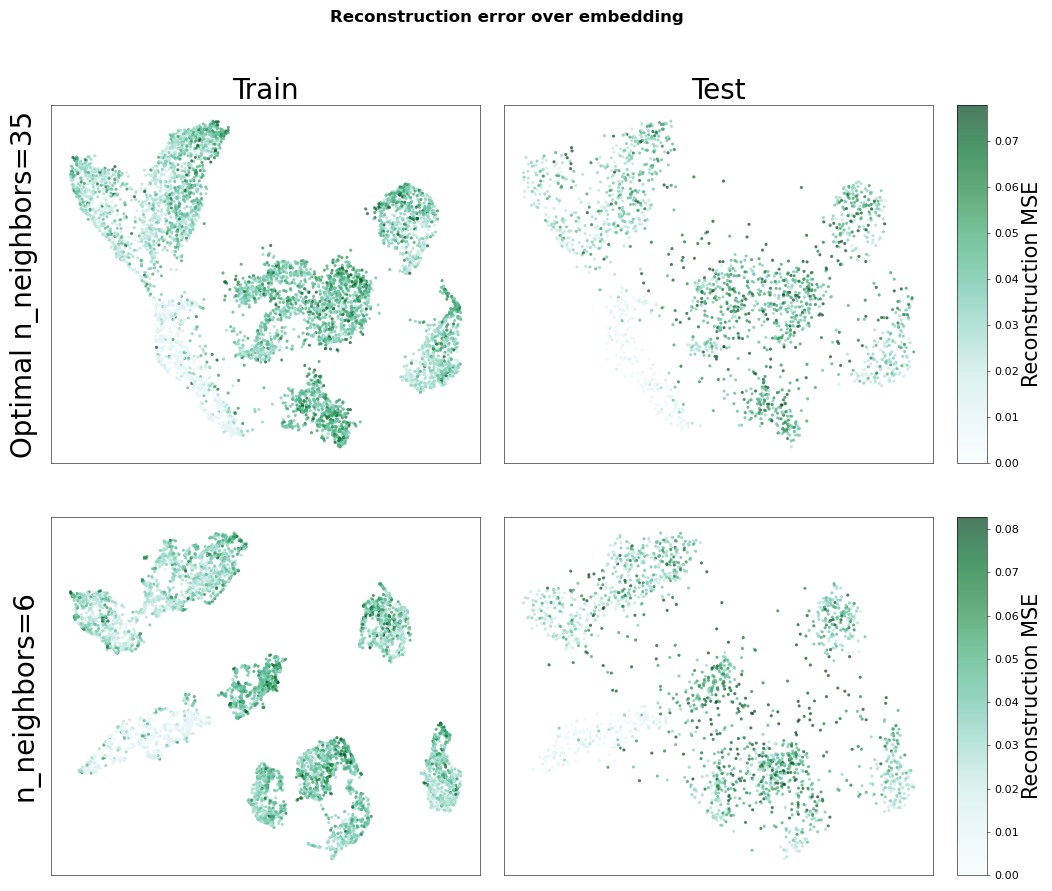

In [35]:
build_distortion_figure(
    emb_data, list_umap_param, umap_one_std_param_choice,
    param_label='n_neighbors', cmap=sns.color_palette("BuGn", as_cmap=True), figsize=(12, 10),
)

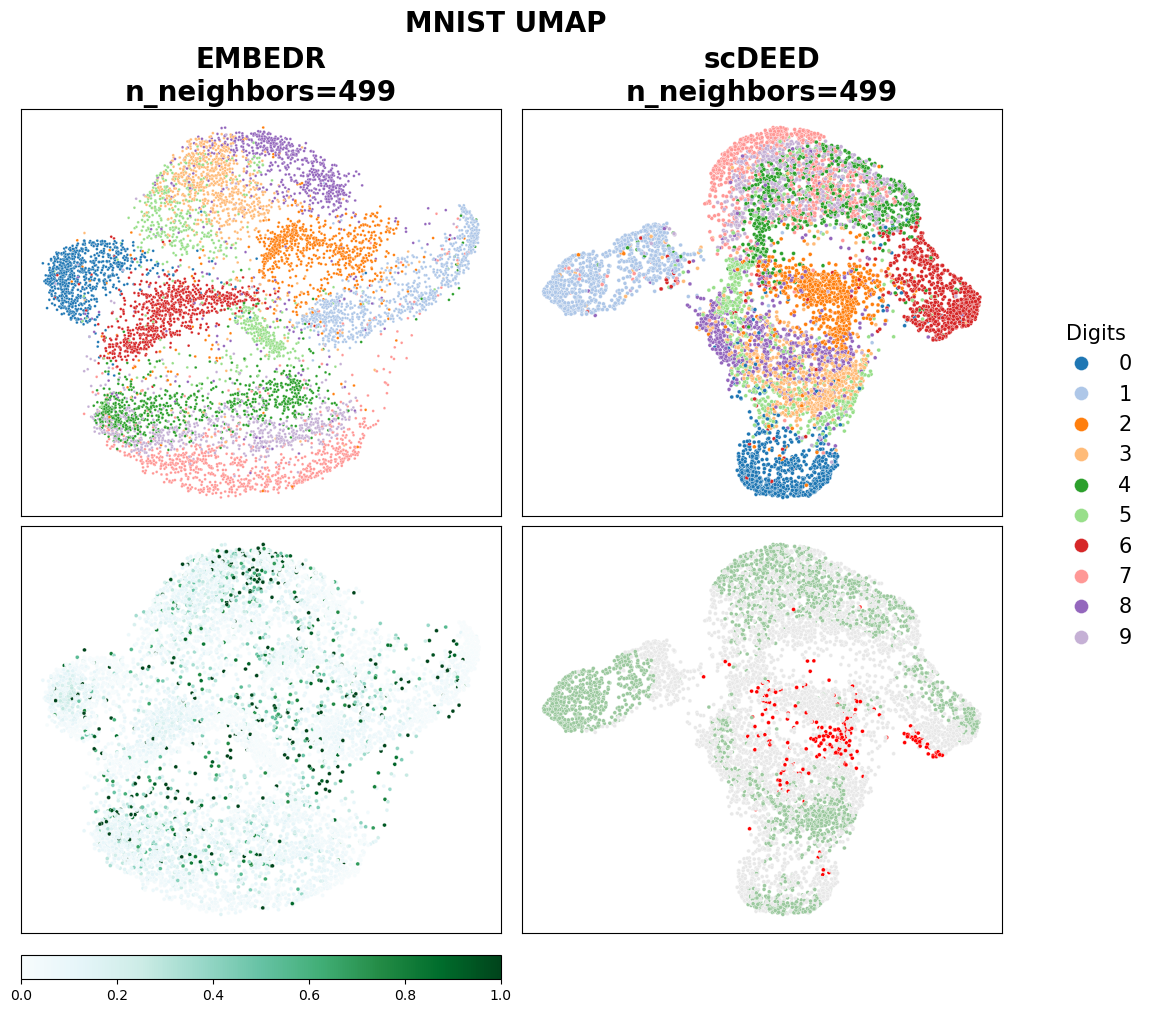

In [213]:
methods = ['scdeed', 'embedr', 'medal']
scdeed_best, embedr_best = 499, 499

teacher_embed = dict.fromkeys(methods)
for m in methods:
    if m == "scdeed":
        teacher_embed[m] = np.load(Path(PATH_PREFIX) / f"MEDAL/comparisons/data/mnist_train_umap_{scdeed_best}_0.1_0_train_pc6.npy")
    else:
        teacher_embed[m] = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings/mnist_umap_{embedr_best}_0.1_0_train_embedr.npy").squeeze(0)
    
embedr_df = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_embedr_umap_seed0/mnist_train/X_with_best_scores.csv')
per_sample_embedr = embedr_df[f'embedr_pval_meanbest_{embedr_best}']

scdeed_df = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_scdeed_umap/seed0/umap_best_mnist_train_full_results.csv', index_col=0)
per_sample_scdeed = split_scdeed_labels(scdeed_df, scdeed_best)['label']
palette_scdeed = {'dubious': 'red', 'intermediate': '#e8e8e8', 'trustworthy': "#9cc99f"}

cmap = sns.color_palette("BuGn", as_cmap=True)
fig, axes = plt.subplots(2, 2, figsize=(10, 10), constrained_layout=True)
axes_flat = axes.flatten()

# 1st column - EMBEDR Sscore
sns.scatterplot(x=teacher_embed['embedr'][:,0], y=teacher_embed['embedr'][:,1], s=4, hue=y_og, palette=mnist_palette, legend=True, ax = axes_flat[0])
sns.scatterplot(x=teacher_embed['embedr'][:,0], y=teacher_embed['embedr'][:,1], hue=per_sample_embedr, palette=cmap, 
                hue_norm=mcolors.Normalize(vmax=np.quantile(per_sample_embedr, 0.975)), 
                s=8,legend=False, rasterized=True, ax = axes_flat[2])
handles, labels = axes_flat[0].get_legend_handles_labels()
if getattr(axes_flat[0], "legend_", None) is not None:
    axes_flat[0].legend_.remove()
    # make one shared legend for the whole figure
    fig.legend(handles, labels,loc='center', bbox_to_anchor=(1.09, 0.52), frameon=False, title='Digits', ncol=1, fontsize=15, markerscale=5, title_fontsize=15)
    
axes_flat[0].set_title(f"EMBEDR\nn_neighbors={embedr_best}", fontsize=20, fontweight='bold')

# 2nd column - Scdeed
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1], 
                ax=axes_flat[1], s=8, hue=y_og, legend=False, palette=mnist_palette)
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1], 
                ax=axes_flat[3], s=8, hue = per_sample_scdeed, palette = palette_scdeed, legend=False)
axes_flat[1].set_title(f"scDEED\nn_neighbors={scdeed_best}", fontsize=20, fontweight='bold')

for ax in axes_flat:
    ax.set_yticks([])
    ax.set_xticks([])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(vmax=np.quantile(per_sample_embedr, 0.975)))
fig.colorbar(sm, ax=axes_flat[2], orientation="horizontal")
fig.suptitle("MNIST UMAP", fontweight='bold', fontsize=20)
plt.show()

/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded par

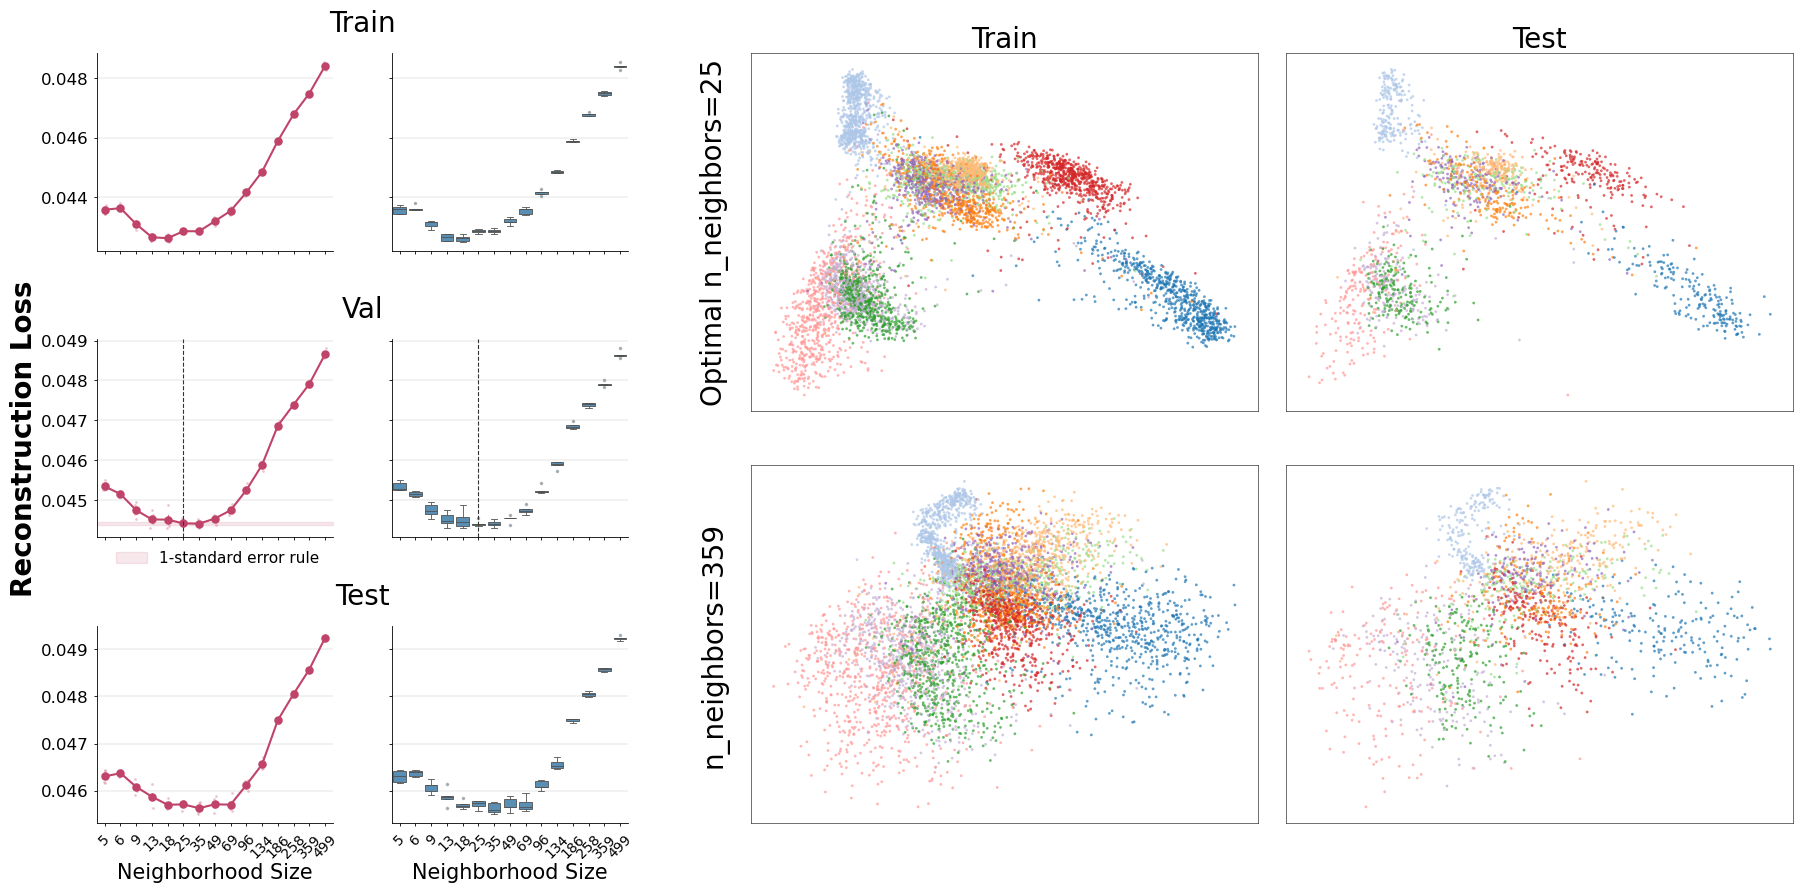

In [11]:
list_spectral_param = [5, 359]
student_spectral01 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/chkpt_teacher_seed/mnist/medal_spectral2_{list_spectral_param[0]}_tc0_0_ckpts/final.pt',
                input_dim=784,
                hidden_dims=[512,512,512,512],
                latent_dim=2, batchnorm=False)
student_recon_spectral01, student_embed_spectral01 = student_spectral01(torch.tensor(X, dtype=torch.float32))
student_recon_val_spectral01, student_embed_val_spectral01 = student_spectral01(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_spectral01, student_embed_test_spectral01 = student_spectral01(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_spectral01 = np.mean((student_recon_spectral01.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_spectral01 = np.mean((student_recon_val_spectral01.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_spectral01 = np.mean((student_recon_test_spectral01.detach().numpy() - X_test)**2, axis=1)

student_spectral02 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/chkpt_teacher_seed/mnist/medal_spectral2_{list_spectral_param[1]}_tc0_0_ckpts/final.pt',
                input_dim=784,
                hidden_dims=[512,512,512,512],
                latent_dim=2, batchnorm=False)
student_recon_spectral02, student_embed_spectral02 = student_spectral02(torch.tensor(X, dtype=torch.float32))
student_recon_val_spectral02, student_embed_val_spectral02 = student_spectral02(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_spectral02, student_embed_test_spectral02 = student_spectral02(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_spectral02 = np.mean((student_recon_spectral02.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_spectral02 = np.mean((student_recon_val_spectral02.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_spectral02 = np.mean((student_recon_test_spectral02.detach().numpy() - X_test)**2, axis=1)

mnist_spectral_res_dict = []
for s in range(5):
    for n in np.unique(np.logspace(np.log10(5), np.log10(500), 15).astype(int)):
        teacher_embed_raw = np.load(
            Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_spectral2_{n}_0_train.npy"
        )
        norm = GlobalEmbeddingNormalizer.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_spectral2_{n}_0_train.norm.pkl")
        teacher_embed = norm.transform(teacher_embed_raw)
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/mnist/medal_spectral2_{n}_tc0_{s}_ckpts/final.pt",
                input_dim=784,
                hidden_dims=[512, 512, 512, 512],
                latent_dim=2, activation=torch.nn.SELU, batchnorm=False)

        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)
        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            mnist_spectral_res_dict.append({"n_neighbors": n, "recon_loss": train_recon, "split": "Train", "seed": s})

            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            mnist_spectral_res_dict.append({"n_neighbors": n, "recon_loss": val_recon, "split": "Val", "seed": s})

            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            mnist_spectral_res_dict.append({"n_neighbors": n, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {n} seed {s} due to distillation loss {train_distill}")

analysis, spectral_one_std_range, spectral_one_std_param_choice, unique_neighbors, vline_x = \
    compute_param_choice(mnist_spectral_res_dict, 'n_neighbors')

emb_data = {
    spectral_one_std_param_choice: {
        'Train': (student_embed_spectral01,      per_sample_recon_spectral01,      y),
        'Val':   (student_embed_val_spectral01,  per_sample_recon_val_spectral01,  y_val),
        'Test':  (student_embed_test_spectral01, per_sample_recon_test_spectral01, y_test),
    },
    list_spectral_param[1]: {
        'Train': (student_embed_spectral02,      per_sample_recon_spectral02,      y),
        'Val':   (student_embed_val_spectral02,  per_sample_recon_val_spectral02,  y_val),
        'Test':  (student_embed_test_spectral02, per_sample_recon_test_spectral02, y_test),
    },
}

build_figure(
    analysis, 'n_neighbors', unique_neighbors, spectral_one_std_range, vline_x,
    emb_data, [spectral_one_std_param_choice, list_spectral_param[1]], spectral_one_std_param_choice,
    mnist_palette, 'n_neighbors', 'Neighborhood Size',
    row_label_y=1.15,
    legend_kw={'frameon': False, 'fontsize': 11, 'loc': 'best', 'bbox_to_anchor': (1, 0)},
    xtick_fontsize=10, figsize=(22, 10),
    share_x_lines=False,
)

In [40]:
mnist_phate_res_dict = []
for s in range(5):
    for n in np.unique(np.logspace(np.log10(5), np.log10(500), 15).astype(int)):
        teacher_embed_raw = np.load(
            Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_phate2_{n}_0_train.npy"
        )
        norm = GlobalEmbeddingNormalizer.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_phate2_{n}_0_train.norm.pkl")
        teacher_embed = norm.transform(teacher_embed_raw)
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/mnist/medal_phate2_{n}_tc0_{s}_ckpts/final.pt",
                input_dim=784,
                hidden_dims=[512, 512, 512, 512], 
                latent_dim=2, activation=torch.nn.SELU, batchnorm=False)
        
        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)
        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            mnist_phate_res_dict.append({"n_neighbors": n, "recon_loss": train_recon, "split": "Train", "seed": s})
            
            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            mnist_phate_res_dict.append({"n_neighbors": n, "recon_loss": val_recon, "split": "Val", "seed": s})
            
            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            mnist_phate_res_dict.append({"n_neighbors": n, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {n} seed {s} due to distillation loss {train_distill}")

/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded par

/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0


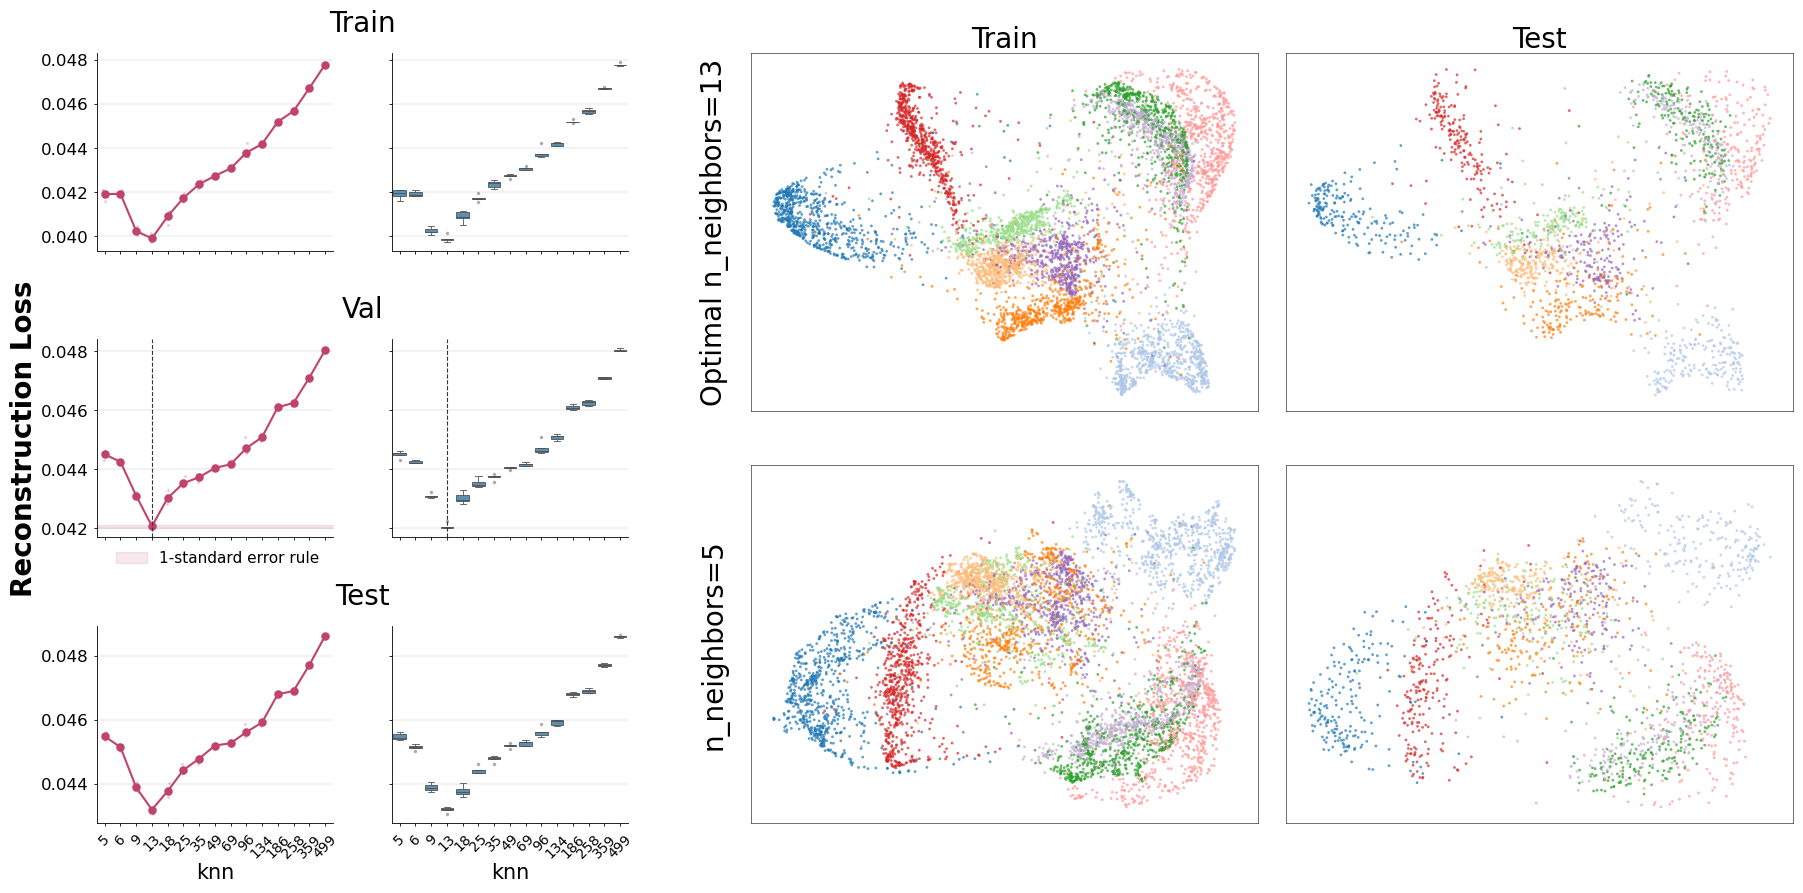

In [43]:
analysis, phate_one_std_range, phate_one_std_param_choice, unique_neighbors, vline_x = \
    compute_param_choice(mnist_phate_res_dict, 'n_neighbors')
list_phate_param = [phate_one_std_param_choice, 5]
student_phate01 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/mnist/medal_phate2_{list_phate_param[0]}_tc0_0_ckpts/final.pt',
                input_dim=784,
                hidden_dims=[512,512,512,512],
                latent_dim=2, batchnorm=False)
student_recon_phate01, student_embed_phate01 = student_phate01(torch.tensor(X, dtype=torch.float32))
student_recon_val_phate01, student_embed_val_phate01 = student_phate01(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_phate01, student_embed_test_phate01 = student_phate01(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_phate01 = np.mean((student_recon_phate01.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_phate01 = np.mean((student_recon_val_phate01.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_phate01 = np.mean((student_recon_test_phate01.detach().numpy() - X_test)**2, axis=1)
student_phate02 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/mnist/medal_phate2_{list_phate_param[1]}_tc0_0_ckpts/final.pt',
                input_dim=784,
                hidden_dims=[512,512,512,512],
                latent_dim=2, batchnorm=False)
student_recon_phate02, student_embed_phate02 = student_phate02(torch.tensor(X, dtype=torch.float32))
student_recon_val_phate02, student_embed_val_phate02 = student_phate02(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_phate02, student_embed_test_phate02 = student_phate02(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_phate02 = np.mean((student_recon_phate02.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_phate02 = np.mean((student_recon_val_phate02.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_phate02 = np.mean((student_recon_test_phate02.detach().numpy() - X_test)**2, axis=1)

emb_data = {
    phate_one_std_param_choice: {
        'Train': (student_embed_phate01,      per_sample_recon_phate01,      y),
        'Val':   (student_embed_val_phate01,  per_sample_recon_val_phate01,  y_val),
        'Test':  (student_embed_test_phate01, per_sample_recon_test_phate01, y_test),
    },
    list_phate_param[1]: {
        'Train': (student_embed_phate02,      per_sample_recon_phate02,      y),
        'Val':   (student_embed_val_phate02,  per_sample_recon_val_phate02,  y_val),
        'Test':  (student_embed_test_phate02, per_sample_recon_test_phate02, y_test),
    },
}
build_figure(
    analysis, 'n_neighbors', unique_neighbors, phate_one_std_range, vline_x,
    emb_data, [phate_one_std_param_choice, list_phate_param[1]], phate_one_std_param_choice,
    mnist_palette, 'n_neighbors', 'knn',
    row_label_y=1.15,
    legend_kw={'frameon': False, 'fontsize': 11, 'loc': 'best', 'bbox_to_anchor': (1, 0)},
    xtick_fontsize=10, figsize=(22, 10),
    share_x_lines=False,
)

In [61]:
tsne_analysis = pd.DataFrame(mnist_tsne_res_dict)
tsne_analysis = tsne_analysis.loc[(tsne_analysis.split=='Val'),:]
tsne_analysis_agg = tsne_analysis.loc[:, ['perplexity','recon_loss']].groupby('perplexity').agg('mean').reset_index()
umap_analysis = pd.DataFrame(mnist_umap_res_dict)
umap_analysis = umap_analysis.loc[(umap_analysis.split=='Val'), :]
umap_analysis_agg = umap_analysis.loc[:, ['n_neighbors','recon_loss']].groupby('n_neighbors').agg('mean').reset_index()
spectral_analysis = pd.DataFrame(mnist_spectral_res_dict)
spectral_analysis = spectral_analysis.loc[(spectral_analysis.split=='Val'), :]
spectral_analysis_agg = spectral_analysis.loc[:, ['n_neighbors','recon_loss']].groupby('n_neighbors').agg('mean').reset_index()
phate_analysis = pd.DataFrame(mnist_phate_res_dict)
phate_analysis = phate_analysis.loc[(phate_analysis.split=='Val'), :]
phate_analysis_agg = phate_analysis.loc[:, ['n_neighbors','recon_loss']].groupby('n_neighbors').agg('mean').reset_index()
pca_analysis = pd.DataFrame(mnist_pca_res_dict)
pca_analysis = pca_analysis.loc[(pca_analysis.split=='Val'), :]

In [62]:
tsne_best = tsne_analysis.loc[tsne_analysis.perplexity == tsne_one_std_param_choice, ['recon_loss', 'seed']]
tsne_best['method'] = f'TSNE(perplexity={tsne_one_std_param_choice})'
umap_best = umap_analysis.loc[umap_analysis.n_neighbors == umap_one_std_param_choice, ['recon_loss', 'seed']]
umap_best['method'] = f'UMAP(n_neighbors={umap_one_std_param_choice})'
spectral_best = spectral_analysis.loc[spectral_analysis.n_neighbors == spectral_one_std_param_choice, ['recon_loss', 'seed']]
spectral_best['method'] = f'Spectral(n_neighbors={spectral_one_std_param_choice})'
phate_best = phate_analysis.loc[phate_analysis.n_neighbors == phate_one_std_param_choice, ['recon_loss', 'seed']]
phate_best['method'] = f'PHATE(knn={phate_one_std_param_choice})'
pca_best = pca_analysis[['recon_loss', 'seed']]
pca_best['method'] = 'PCA'
teachers = pd.concat([tsne_best, umap_best, spectral_best, pca_best, phate_best])

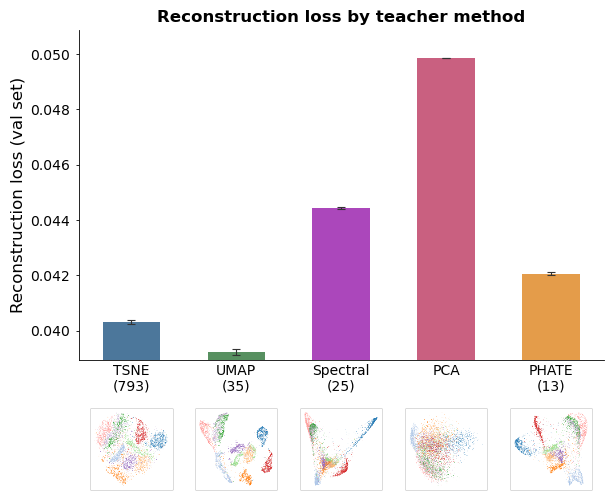

In [64]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

embeddings = {
    'TSNE(perplexity=793)': np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_tsne_{tsne_one_std_param_choice}_0_train.npy"),
    f'UMAP(n_neighbors={umap_one_std_param_choice})':np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_umap_{umap_one_std_param_choice}_0.1_0_train.npy"),
    f'PHATE(knn={phate_one_std_param_choice})': np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_phate2_{phate_one_std_param_choice}_0_train.npy"),
    f'Spectral(n_neighbors={spectral_one_std_param_choice})': np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_spectral_{spectral_one_std_param_choice}_0_train.npy"),
    'PCA': np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_pca2_0_train.npy"),
}

method_order = ['TSNE(perplexity=793)', f'UMAP(n_neighbors={umap_one_std_param_choice})',
                f'Spectral(n_neighbors={spectral_one_std_param_choice})', 'PCA', 
                f'PHATE(knn={phate_one_std_param_choice})'
               ]

short_labels = {
    'TSNE(perplexity=793)':  'TSNE\n(793)',
    f'UMAP(n_neighbors={umap_one_std_param_choice})':  f'UMAP\n({umap_one_std_param_choice})',
    f'Spectral(n_neighbors={spectral_one_std_param_choice})': f'Spectral\n({spectral_one_std_param_choice})',
    'PCA':                   'PCA',
    f'PHATE(knn={phate_one_std_param_choice})':         f'PHATE\n({phate_one_std_param_choice})',
}

method_colors = {
    'TSNE(perplexity=793)':  '#2C5F8A',
    f'UMAP(n_neighbors={umap_one_std_param_choice})':  '#3A7D44',
    f'Spectral(n_neighbors={spectral_one_std_param_choice})': '#9C27B0',
    'PCA':                   '#C0446A',
    f'PHATE(knn={phate_one_std_param_choice})':         '#E08B2A',
}

stats = (teachers.groupby('method')['recon_loss']
         .agg(mean='mean', se=lambda x: x.sem())
         .reindex(method_order)
         .reset_index())

plt.rcParams.update({
    'font.family':          'sans-serif',
    'font.sans-serif':      ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':            8,
    'axes.labelsize':       10,
    'axes.titlesize':       12,
    'xtick.labelsize':      10,
    'ytick.labelsize':      10,
    'axes.linewidth':       0.6,
    'xtick.major.width':    0.6,
    'ytick.major.width':    0.6,
    'xtick.major.size':     2.5,
    'ytick.major.size':     2.5,
    'pdf.fonttype':         42,
    'ps.fonttype':          42,
})

fig, ax = plt.subplots(figsize=(7, 5.5))   
fig.subplots_adjust(bottom=0.28)  

x = np.arange(len(method_order))
bar_w = 0.55

bars = ax.bar(
    x, stats['mean'],
    width=bar_w,
    color=[method_colors[m] for m in stats['method']],
    alpha=0.85,
    zorder=3,
)

ax.errorbar(
    x, stats['mean'],
    yerr=stats['se'],
    fmt='none',
    ecolor='#333333',
    elinewidth=0.8,
    capsize=3,
    capthick=0.8,
    zorder=4,
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.6)
ax.spines['bottom'].set_linewidth(0.6)

ax.set_ylabel('Reconstruction loss (val set)', labelpad=4, fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(['' ] * len(method_order)) 
ax.tick_params(axis='x', length=0)            

for i, method in enumerate(method_order):
    ax.text(i, -0.01, short_labels[method],
            ha='center', va='top',
            fontsize=10, 
            transform=ax.get_xaxis_transform())

thumb_zoom = 0.32
ymin = (stats['mean'] - stats['se']).min()
ax.set_ylim(ymin * 0.995, (stats['mean'] + stats['se']).max() * 1.02)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
fig.subplots_adjust(bottom=0.28, left=0.15)

for i, method in enumerate(method_order):
    Z = embeddings[method]

    fig_tmp, ax_tmp = plt.subplots(figsize=(1.8, 1.8))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1],
                    hue=y, palette=mnist_palette, ax=ax_tmp,
                    legend=False, s=0.5,
                    linewidths=0, rasterized=True)
    ax_tmp.axis('off')
    fig_tmp.tight_layout(pad=0)
    fig_tmp.canvas.draw()
    img = np.asarray(fig_tmp.canvas.buffer_rgba())[..., :3]  
    plt.close(fig_tmp)

    imagebox = OffsetImage(img, zoom=thumb_zoom)
    ab = AnnotationBbox(
        imagebox,
        xy=(i, 0),
        xycoords=('data', 'axes fraction'),
        box_alignment=(0.5, 1.0),
        xybox=(0, -35),               
        boxcoords='offset points',
        frameon=True,
        bboxprops=dict(edgecolor='#cccccc', linewidth=0.5,
                       boxstyle='round,pad=0.1'),
    )
    ax.add_artist(ab)

ax.set_title('Reconstruction loss by teacher method', fontweight='bold', pad=6)
plt.show()

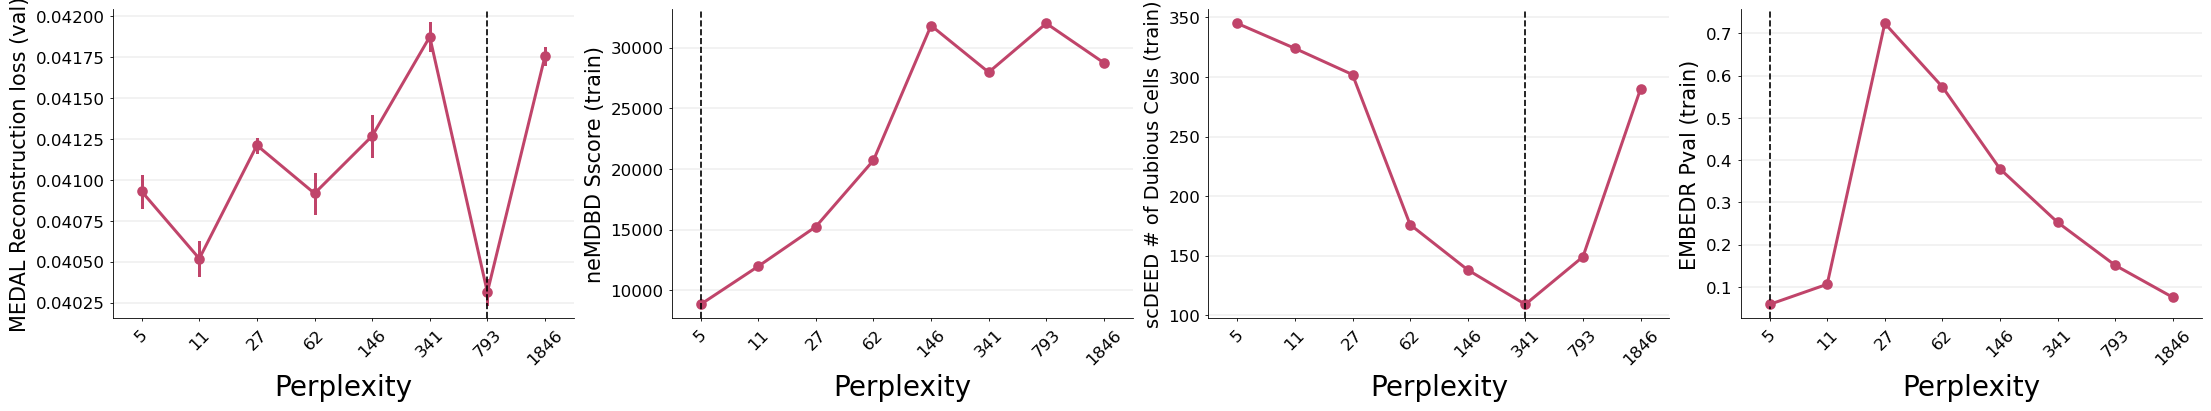

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(22,4), constrained_layout=True)
axes_flat = axes.flatten()
## MEDAL
analysis, tsne_one_std_range, tsne_one_std_param_choice, unique_perplexities, vline_x = \
    compute_param_choice(mnist_tsne_res_dict, 'perplexity')
sns.pointplot(data=analysis.loc[analysis.split == "Val"], x="perplexity", y="recon_loss", color="#C0446A", markersize=6, ax=axes_flat[0], 
             errorbar='se')
axes_flat[0].set_ylabel("MEDAL Reconstruction loss (val)", fontsize=15)    
axes_flat[0].axvline(x=unique_perplexities.index(tsne_one_std_param_choice), ls='--', c='black')

## neMDBD Score
pcs_ = pd.read_csv(Path(PATH_PREFIX) / f'MEDAL/comparisons/results_pcs_seed0/mnist_train/elbow_df.csv')
pcs_.sort_values(by='perplexity', inplace=True)
unique_perp = sorted(pcs_['perplexity'].unique())
pcs_tsne_argmin_sscore = pcs_.groupby('perplexity')['mean_sscore'].mean().idxmin()
pos_mean_sscore = unique_perp.index(pcs_tsne_argmin_sscore)
sns.pointplot(data=pcs_, x="perplexity", y="mean_sscore", color="#C0446A", markersize=6, ax=axes_flat[1])
axes_flat[1].set_ylabel("neMDBD Sscore (train)", fontsize=15)    
axes_flat[1].axvline(x=pos_mean_sscore, ls='--', c='black')
## scDEED
scdeed_analysis = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_mnist_train_num_dubious.csv')
umap_argmin = scdeed_analysis['number_dubious_cells'].idxmin()
argmin_position = scdeed_analysis.index.tolist().index(umap_argmin)
sns.pointplot(data=scdeed_analysis, x='perplexity', y='number_dubious_cells', color='#C0446A', markersize=6, ax = axes_flat[2])
axes_flat[2].axvline(x = argmin_position, ls = '--', c ='black')
axes_flat[2].set_ylabel("scDEED # of Dubious Cells (train)", fontsize=14)
## EMBEDR algorithm
embedr_ = pd.read_csv(Path(PATH_PREFIX)/ f'MEDAL/comparisons/results_embedr_tsne_seed0/mnist_train/elbow_df.csv')
embedr_.sort_values(by='perplexity', inplace=True)
embedr_tsne_argmin = embedr_.groupby('perplexity')['mean_embedr_pval'].mean().idxmin()
unique_perp = sorted(embedr_['perplexity'].unique())
pos_mean = unique_perp.index(embedr_tsne_argmin)
sns.pointplot(data=embedr_, x="perplexity", y="mean_embedr_pval", color="#C0446A", markersize=6, ax = axes_flat[3])
sns.stripplot(data=embedr_, x="perplexity", y="mean_embedr_pval", color="#C0446A", size=3, ax = axes_flat[3])
axes_flat[3].set_ylabel("EMBEDR Pval (train)", fontsize=15)       
axes_flat[3].axvline(x=pos_mean, ls='--', c='black')
for ax in axes_flat:
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_linewidth(0.6)
    ax.grid(axis='y', linewidth=0.35, color='gray', alpha=0.4, zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=12)
    ax.set_xlabel("Perplexity", fontsize=20)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='center')
plt.show()

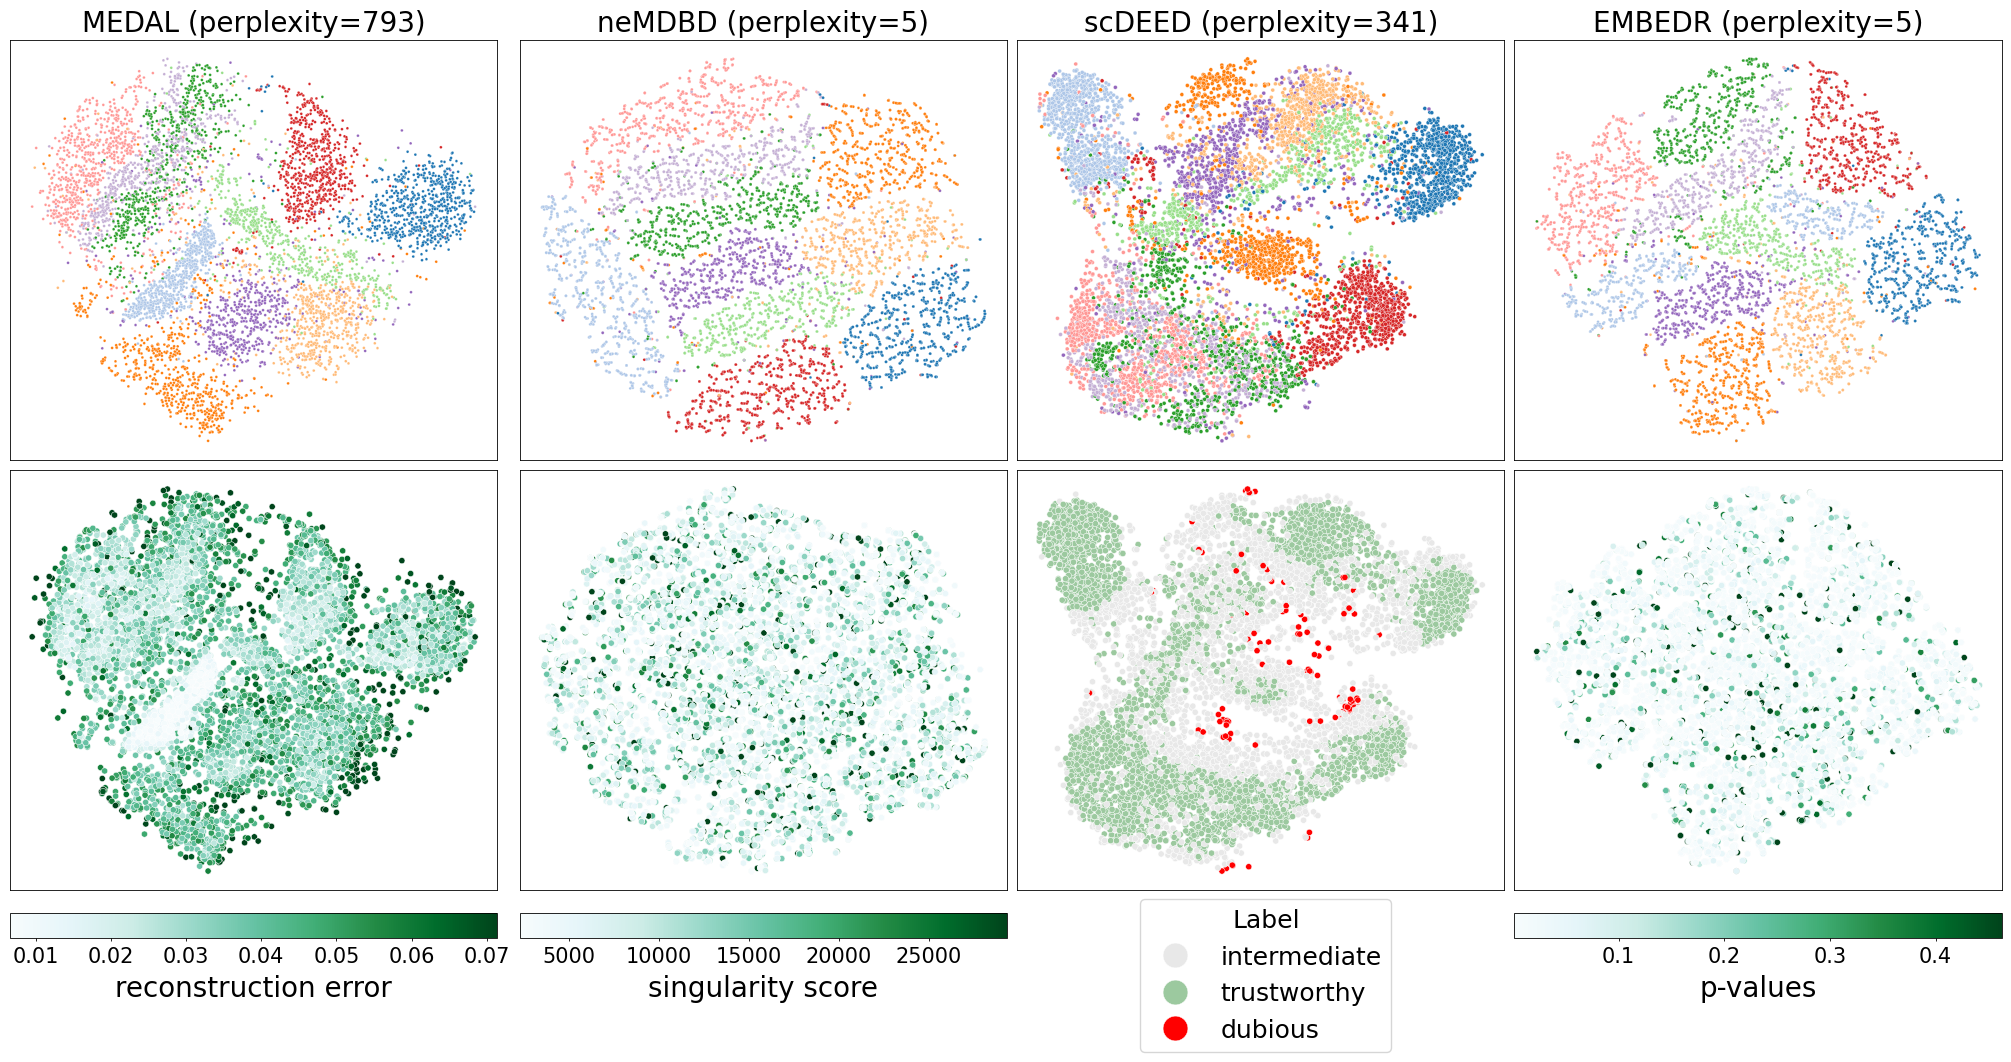

In [22]:
methods = ['pcs_ss', 'scdeed', 'embedr', 'medal']
pcs_ss_best, scdeed_best, embedr_best, medal_best = 5, 341, 5, 793
teacher_embed = dict.fromkeys(methods)
teacher_embed['scdeed'] = np.load(Path(PATH_PREFIX) / f"MEDAL/comparisons/data/mnist_train_tsne_{scdeed_best}_0_train_pc6.npy")
teacher_embed['pcs_ss'] = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings/mnist_tsne_{pcs_ss_best}_0_train_pcs.npy")
teacher_embed['medal'] = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_tsne_{medal_best}_0_train.npy")
teacher_embed['embedr'] = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings/mnist_tsne_{embedr_best}_0_train_embedr.npy").squeeze(0)
pcs_df = pd.read_csv(Path(PATH_PREFIX) /'MEDAL/comparisons/results_pcs_seed0/mnist_train/scores_per_point_all_perplexities.csv')
per_sample_pcs_ss = pcs_df.loc[pcs_df.perplexity == pcs_ss_best, "sscore"]
embedr_df = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_embedr_tsne_seed0/mnist_train/X_with_best_scores.csv')
per_sample_embedr = embedr_df[f'embedr_pval_meanbest_{embedr_best}']
scdeed_df = pd.read_csv(Path(PATH_PREFIX) / "MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_mnist_train_full_results.csv", index_col=0)
per_sample_scdeed = split_scdeed_labels(scdeed_df, scdeed_best)['label']
palette_scdeed = {'dubious': 'red', 'intermediate': '#e8e8e8', 'trustworthy': "#9cc99f"}
cmap = sns.color_palette("BuGn", as_cmap=True)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
axes_flat = axes.flatten()

# 1st column - MEDAL
sns.scatterplot(x=teacher_embed['medal'][:,0], y=teacher_embed['medal'][:,1], s=4, hue=y, palette=mnist_palette, legend=False, ax=axes_flat[0])
sns.scatterplot(x=teacher_embed['medal'][:,0], y=teacher_embed['medal'][:,1], hue=per_sample_recon_umap01, palette=cmap,
                hue_norm=plt.Normalize(vmin=np.quantile(per_sample_recon_umap01, 0.025), vmax=np.quantile(per_sample_recon_umap01, 0.975)),
                s=20, legend=False, rasterized=True, ax=axes_flat[4])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(per_sample_recon_umap01, 0.025), vmax=np.quantile(per_sample_recon_umap01, 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[4], orientation="horizontal")
cb.set_label("reconstruction error", fontsize=20, labelpad=6)

# 2nd column - PCS Sscore
sns.scatterplot(x=teacher_embed['pcs_ss'][:,0], y=teacher_embed['pcs_ss'][:,1], s=4, hue=y_og, palette=mnist_palette, legend=False, ax=axes_flat[1])
sns.scatterplot(x=teacher_embed['pcs_ss'][:,0], y=teacher_embed['pcs_ss'][:,1], hue=per_sample_pcs_ss, palette=cmap, 
                hue_norm=plt.Normalize(vmin=np.quantile(per_sample_pcs_ss, 0.025), vmax=np.quantile(per_sample_pcs_ss, 0.975)), 
                s=20, legend=False, rasterized=True, ax=axes_flat[5])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(per_sample_pcs_ss, 0.025), vmax=np.quantile(per_sample_pcs_ss, 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[5], orientation="horizontal")
cb.set_label("singularity score", fontsize=20, labelpad=6)

# 3rd column - scDEED
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1], 
                ax=axes_flat[2], s=8, hue=y_og, legend=False, palette=mnist_palette)
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1], 
                ax=axes_flat[6], s=20, hue=per_sample_scdeed, palette=palette_scdeed, legend=True)
handles, labels = axes_flat[6].get_legend_handles_labels()
if getattr(axes_flat[6], "legend_", None) is not None:
    axes_flat[6].legend_.remove()
    fig.legend(handles, labels, loc='center', bbox_to_anchor=(0.63, 0.03), frameon=True, title='Label', ncol=1, fontsize=18, markerscale=4, title_fontsize=18)

# 4th column - EMBEDR
sns.scatterplot(x=teacher_embed['embedr'][:,0], y=teacher_embed['embedr'][:,1], s=4, hue=y_og, palette=mnist_palette, legend=False, ax=axes_flat[3])
sns.scatterplot(x=teacher_embed['embedr'][:,0], y=teacher_embed['embedr'][:,1], hue=per_sample_embedr, palette=cmap, 
                hue_norm=plt.Normalize(vmin=np.quantile(per_sample_embedr, 0.025), vmax=np.quantile(per_sample_embedr, 0.975)), 
                s=20, legend=False, rasterized=True, ax=axes_flat[7])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(per_sample_embedr, 0.025), vmax=np.quantile(per_sample_embedr, 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[7], orientation="horizontal")
cb.set_label("p-values", fontsize=20, labelpad=6)

axes_flat[0].set_title(f"MEDAL (perplexity={medal_best})", fontsize=20)
axes_flat[1].set_title(f"neMDBD (perplexity={pcs_ss_best})", fontsize=20)
axes_flat[2].set_title(f"scDEED (perplexity={scdeed_best})", fontsize=20)
axes_flat[3].set_title(f"EMBEDR (perplexity={embedr_best})", fontsize=20)

for ax in axes_flat:
    ax.set_yticks([])
    ax.set_xticks([])
plt.show()

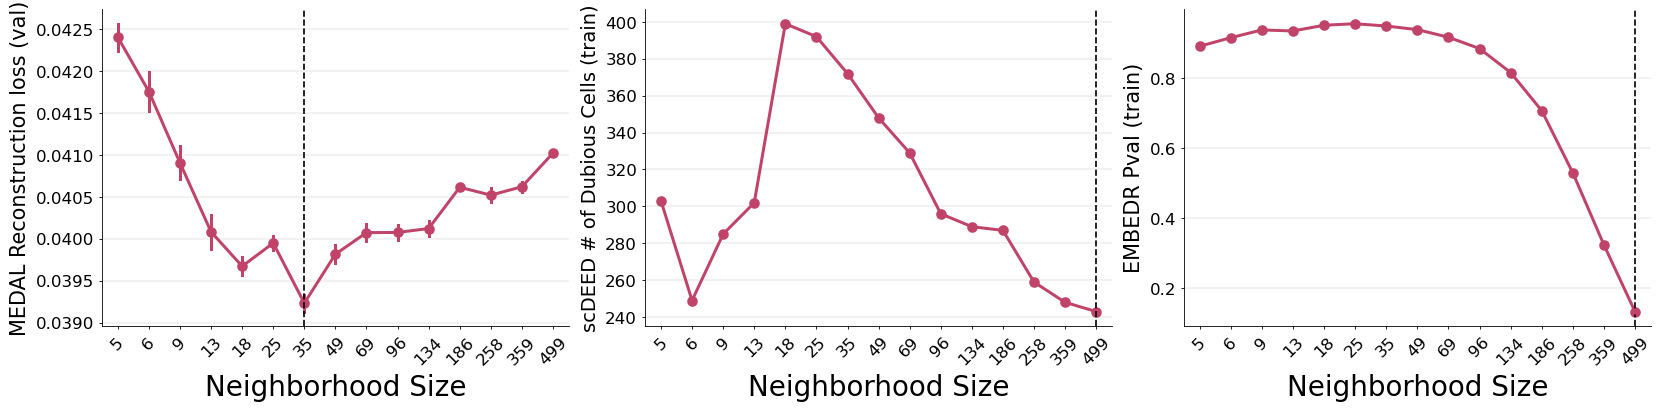

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4), constrained_layout=True)
axes_flat = axes.flatten()

## MEDAL
analysis, umap_one_std_range, umap_one_std_param_choice, unique_nn, vline_x = \
    compute_param_choice(mnist_umap_res_dict, 'n_neighbors')
sns.pointplot(data=analysis.loc[analysis.split == "Val"], x="n_neighbors", y="recon_loss", color="#C0446A", markersize=6, ax=axes_flat[0], 
              errorbar='se')
axes_flat[0].set_ylabel("MEDAL Reconstruction loss (val)", fontsize=15)
axes_flat[0].axvline(x=unique_nn.index(umap_one_std_param_choice), ls='--', c='black')

## scDEED
scdeed_analysis = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_scdeed_umap/seed0/umap_best_mnist_train_num_dubious.csv')
umap_argmin = scdeed_analysis['number_dubious_cells'].idxmin()
argmin_position = scdeed_analysis.index.tolist().index(umap_argmin)
sns.pointplot(data=scdeed_analysis, x='n_neighbors', y='number_dubious_cells', color='#C0446A', markersize=6, ax=axes_flat[1])
axes_flat[1].axvline(x=argmin_position, ls='--', c='black')
axes_flat[1].set_ylabel("scDEED # of Dubious Cells (train)", fontsize=14)

## EMBEDR algorithm
embedr_ = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_embedr_umap_seed0/mnist_train/elbow_df.csv')
embedr_.sort_values(by='n_neighbors', inplace=True)
embedr_umap_argmin = embedr_.groupby('n_neighbors')['mean_embedr_pval'].mean().idxmin()
unique_nn = sorted(embedr_['n_neighbors'].unique())
pos_mean = unique_nn.index(embedr_umap_argmin)
sns.pointplot(data=embedr_, x="n_neighbors", y="mean_embedr_pval", color="#C0446A", markersize=6, ax=axes_flat[2])
sns.stripplot(data=embedr_, x="n_neighbors", y="mean_embedr_pval", color="#C0446A", size=3, ax=axes_flat[2])
axes_flat[2].set_ylabel("EMBEDR Pval (train)", fontsize=15)
axes_flat[2].axvline(x=pos_mean, ls='--', c='black')

for ax in axes_flat:
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_linewidth(0.6)
    ax.grid(axis='y', linewidth=0.35, color='gray', alpha=0.4, zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=12)
    ax.set_xlabel("Neighborhood Size", fontsize=20)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='center')

plt.show()

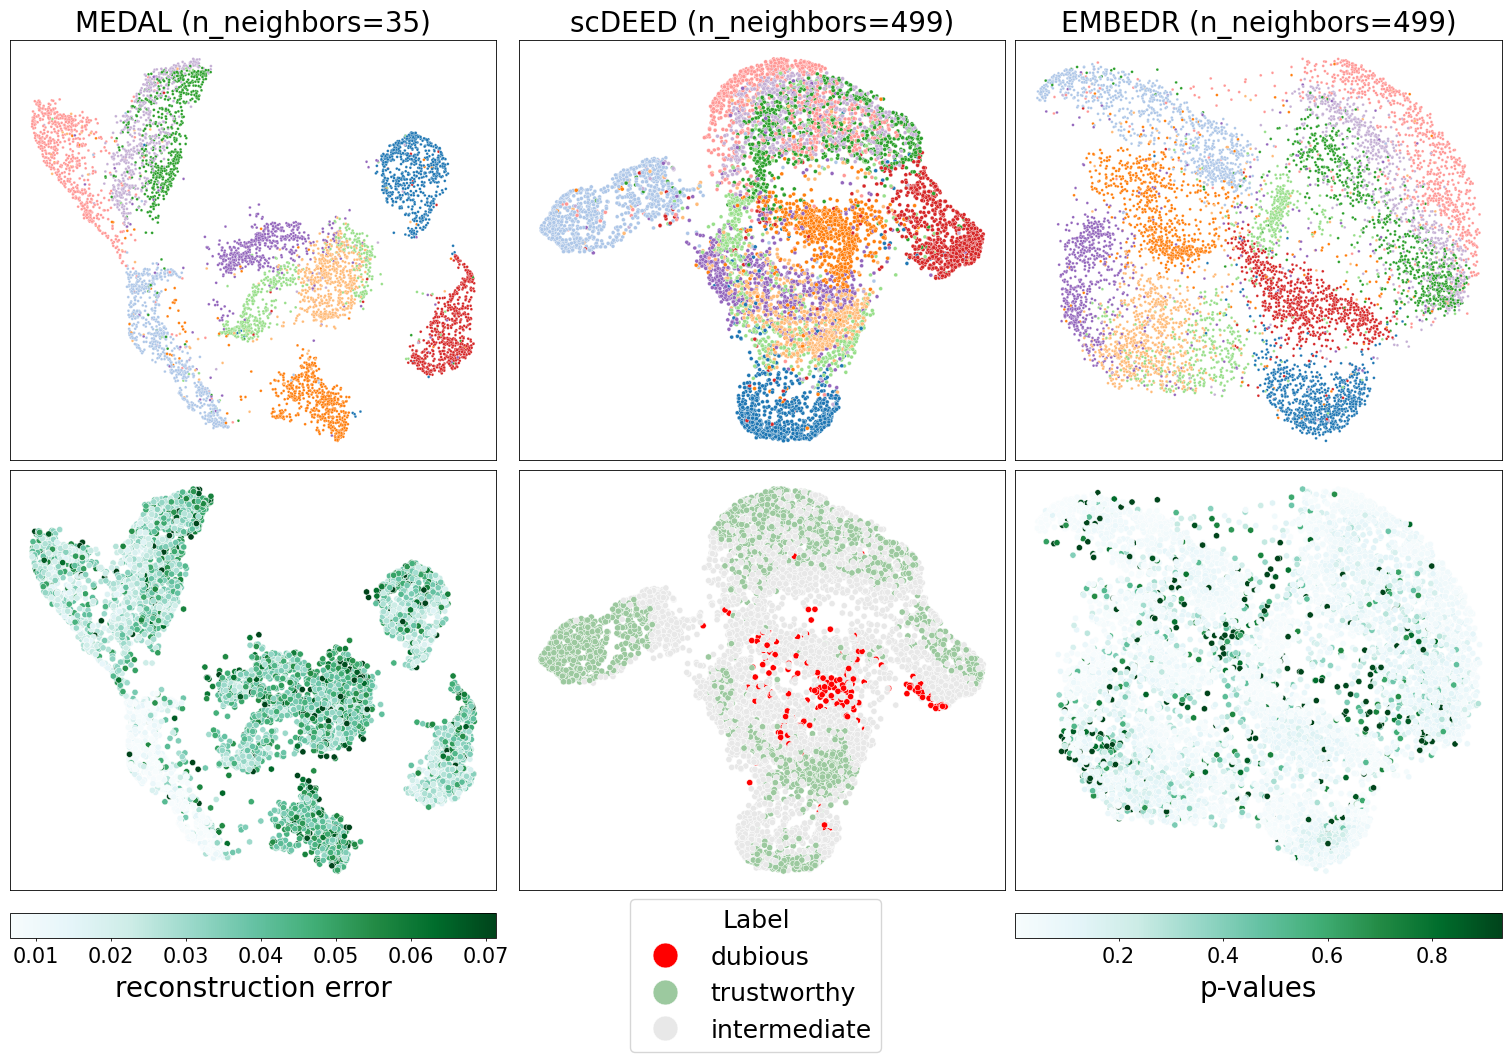

In [32]:
methods = ['scdeed', 'embedr']
scdeed_best, embedr_best = 499, 499

teacher_embed = dict.fromkeys(methods)
teacher_embed['scdeed'] = np.load(Path(PATH_PREFIX) / f"MEDAL/comparisons/data/mnist_train_umap_{scdeed_best}_0.1_0_train_pc6.npy")
teacher_embed['embedr'] = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings/mnist_umap_{embedr_best}_0.1_2_train_embedr.npy").squeeze(0)

embedr_df = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_embedr_umap_seed2/mnist_train/X_with_best_scores.csv')
per_sample_embedr = embedr_df[f'embedr_pval_meanbest_{embedr_best}']

scdeed_df = pd.read_csv(Path(PATH_PREFIX) / "MEDAL/comparisons/results_scdeed_umap/seed0/umap_best_mnist_train_full_results.csv", index_col=0)
per_sample_scdeed = split_scdeed_labels(scdeed_df, scdeed_best)['label']
palette_scdeed = {'dubious': 'red', 'intermediate': '#e8e8e8', 'trustworthy': "#9cc99f"}

cmap = sns.color_palette("BuGn", as_cmap=True)
fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
axes_flat = axes.flatten()

# 1st column - MEDAL
medal_data_to_plot = (student_embed_umap01,  per_sample_recon_umap01,  y)
sns.scatterplot(x=medal_data_to_plot[0].detach().numpy()[:, 0],
                y=medal_data_to_plot[0].detach().numpy()[:, 1],
                s=4, hue=y, palette=mnist_palette, legend=False, ax=axes_flat[0])
sns.scatterplot(x=medal_data_to_plot[0].detach().numpy()[:, 0],
                y=medal_data_to_plot[0].detach().numpy()[:, 1],
                hue=medal_data_to_plot[1], palette=cmap,
                hue_norm=plt.Normalize(vmin=np.quantile(medal_data_to_plot[1], 0.025),
                                       vmax=np.quantile(medal_data_to_plot[1], 0.975)),
                s=20, legend=False, rasterized=True, ax=axes_flat[3])
axes_flat[0].set_title(f"MEDAL (n_neighbors={umap_one_std_param_choice})", fontsize=20)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(medal_data_to_plot[1], 0.025),
                                                          vmax=np.quantile(medal_data_to_plot[1], 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[3], orientation="horizontal")
cb.set_label("reconstruction error", fontsize=20, labelpad=6)

# 2nd column - scDEED
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1],
                ax=axes_flat[1], s=8, hue=y_og, legend=False, palette=mnist_palette)
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1],
                ax=axes_flat[4], s=20, hue=per_sample_scdeed, palette=palette_scdeed, legend=True)
handles, labels = axes_flat[4].get_legend_handles_labels()
if getattr(axes_flat[4], "legend_", None) is not None:
    axes_flat[4].legend_.remove()
    fig.legend(handles, labels, loc='center', bbox_to_anchor=(0.5, 0.03), frameon=True,
               title='Label', ncol=1, fontsize=18, markerscale=4, title_fontsize=18)
axes_flat[1].set_title(f"scDEED (n_neighbors={scdeed_best})", fontsize=20)

# 3rd column - EMBEDR
sns.scatterplot(x=teacher_embed['embedr'][:, 0], y=teacher_embed['embedr'][:, 1],
                s=4, hue=y_og, palette=mnist_palette, legend=False, ax=axes_flat[2])
sns.scatterplot(x=teacher_embed['embedr'][:, 0], y=teacher_embed['embedr'][:, 1],
                hue=per_sample_embedr, palette=cmap,
                hue_norm=plt.Normalize(vmin=np.quantile(per_sample_embedr, 0.025),
                                       vmax=np.quantile(per_sample_embedr, 0.975)),
                s=20, legend=False, rasterized=True, ax=axes_flat[5])
axes_flat[2].set_title(f"EMBEDR (n_neighbors={embedr_best})", fontsize=20)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(per_sample_embedr, 0.025),
                                                          vmax=np.quantile(per_sample_embedr, 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[5], orientation="horizontal")
cb.set_label("p-values", fontsize=20, labelpad=6)

for ax in axes_flat:
    ax.set_yticks([])
    ax.set_xticks([])
plt.show()

In [47]:
mnist_pca_res_dict = []
for s in range(5):
    for comp in np.unique(np.logspace(np.log10(2), np.log10(500), 15).astype(int)):
        teacher_embed_raw = np.load(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/mnist/embeddings/data_pca{comp}_train.npy")
        norm = GlobalEmbeddingNormalizer.load(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/mnist/embeddings/data_pca{comp}_train.norm.pkl")
        teacher_embed = norm.transform(teacher_embed_raw)
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/mnist/medal_pca{comp}_{comp}_seed{s}_ckpts/final.pt",
                input_dim=784,
                hidden_dims=[512, 512, 512, 512],
                latent_dim=comp, activation=torch.nn.SELU, batchnorm=False)
        
        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)
        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            mnist_pca_res_dict.append({"n_components": comp, "recon_loss": train_recon, "split": "Train", "seed": s})
            
            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            mnist_pca_res_dict.append({"n_components": comp, "recon_loss": val_recon, "split": "Val", "seed": s})

            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            mnist_pca_res_dict.append({"n_components": comp, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {perp} seed {s} due to distillation loss {train_distill}")

/tmp/ipykernel_46115/307597701.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded params: 20 | missing=0 | unexpected=0
loaded par

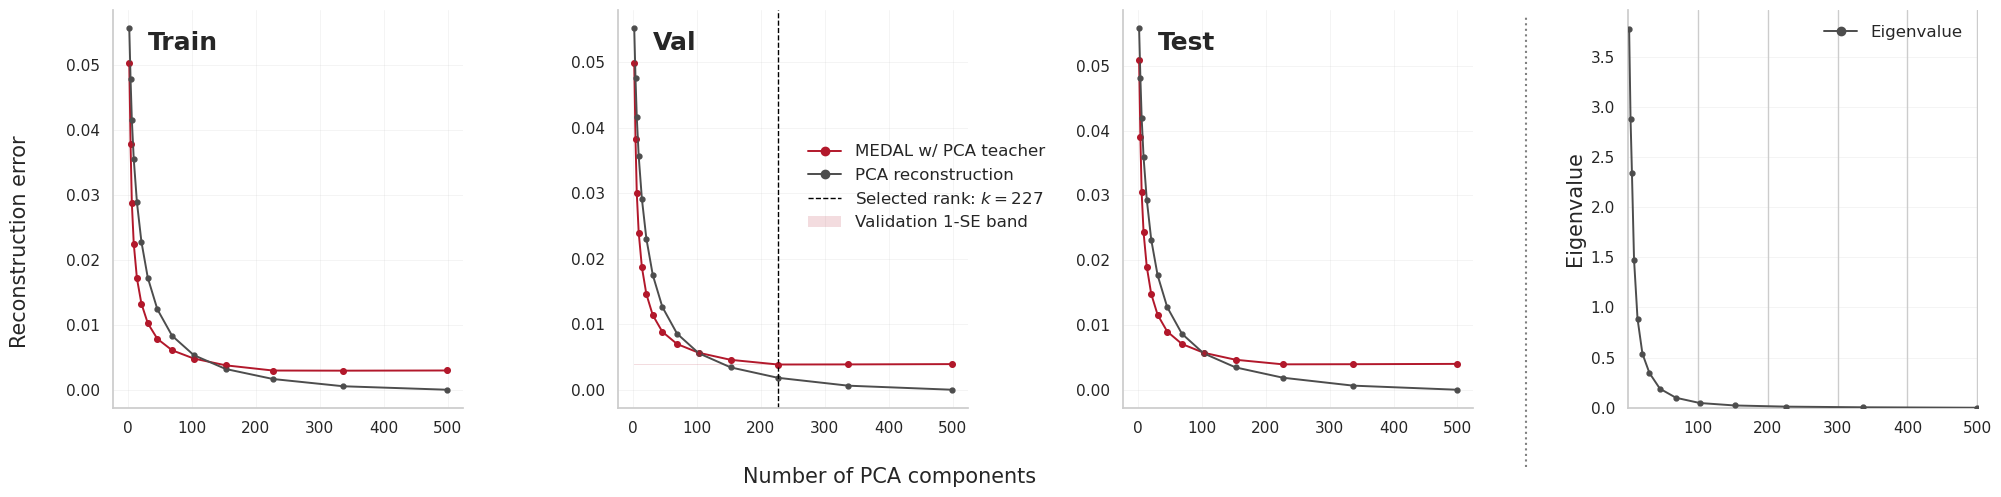

In [88]:
from matplotlib.patches import Patch

pca = PCA().fit(X)
A = pd.DataFrame(mnist_pca_res_dict).sort_values("n_components")
K = np.array(sorted(A.n_components.unique()))
S = (A[A.split.eq("Val")]
     .groupby("n_components")
     .agg(mean=("recon_loss", "mean"), sem=("recon_loss", "sem")))
best_k = S["mean"].idxmin()
lo, hi = S.loc[best_k, "mean"] - S.loc[best_k, "sem"], S.loc[best_k, "mean"] + S.loc[best_k, "sem"]
sel_k = S[(S["mean"].between(lo, hi))].index.min()
ranks = K

def pca_recon(X_):
    Z = pca.transform(X_)
    return np.array([
        np.mean((X_ - pca.inverse_transform(np.pad(Z[:, :k], ((0, 0), (0, Z.shape[1] - k))))) ** 2)
        for k in ranks
    ])
eigenvalues = pca.explained_variance_         

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(
    1, 4, figsize=(20, 5),
    gridspec_kw={"width_ratios": [1, 1, 1, 1]},
)

colors = {"medal": "#B2182B", "pca": "#4D4D4D", "cum": "#2166AC"}
Xs = {"Train": X, "Val": X_val, "Test": X_test}

# ── Left three panels - MEDAL ─────────────────────────────────────
for ax, (split, X_) in zip(axes[:3], Xs.items()):
    sub = A[A.split.eq(split)]
    sns.stripplot(data=sub, x="n_components", y="recon_loss",
                  color=colors["medal"], size=3, alpha=.35, jitter=.1,
                  native_scale=True, ax=ax)
    sns.pointplot(data=sub, x="n_components", y="recon_loss",
                  errorbar="se", color=colors["medal"], markers="o",
                  markersize=4, linewidth=1.4, native_scale=True, ax=ax)
    ax.plot(ranks, pca_recon(X_), "-o", color=colors["pca"], ms=3.5, lw=1.4)
    if split == "Val":
        ax.axvline(sel_k, c="black", ls="--", lw=1)
    ax.text(.1, .9, split, transform=ax.transAxes, weight="bold", fontsize=18)
    ax.set(xlabel="", ylabel="")
    ax.grid(alpha=.25, lw=.6)
    ax.spines[["top", "right"]].set_visible(False)

axes[1].fill_between(K, lo, hi, color=colors["medal"], alpha=.15, lw=0)

legend_handles = [
    Line2D([0], [0], color=colors["medal"], marker="o", lw=1.4,
           label="MEDAL w/ PCA teacher"),
    Line2D([0], [0], color=colors["pca"], marker="o", lw=1.4,
           label="PCA reconstruction"),
    Line2D([0], [0], color="black", ls="--", lw=1,
           label=f"Selected rank: $k={sel_k}$"),
    Patch(facecolor=colors["medal"], alpha=.15, edgecolor="none",
          label="Validation 1-SE band"),
]
axes[1].legend(handles=legend_handles, frameon=False, fontsize=12,
               bbox_to_anchor=(0.5, 0.7))

# ── Panel 4: Scree plot ──────────────────────────────────────────────────────
ax_scree = axes[3]

ax_scree.plot(ranks, eigenvalues[ranks -1],
              "-o", color=colors["pca"], lw=1.4, ms=3.5, zorder=3)

ax_scree.set_xlim(0.5, 500.5)
ax_scree.set_ylim(bottom=0)
ax_scree.set_ylabel("Eigenvalue",           fontsize=15)
ax_scree.grid(alpha=.25, lw=.6, axis="y")
ax_scree.spines[["top", "right"]].set_visible(False)

scree_handles = [
    Line2D([0], [0], color=colors["pca"], marker="o", lw=1.4, label="Eigenvalue"),
]
ax_scree.legend(handles=scree_handles, frameon=False, fontsize=12, loc="upper right")

fig.canvas.draw()                          
pos3 = axes[2].get_position()             
pos4 = axes[3].get_position()             
x_divider = pos3.x1 + 0.06     

line = plt.Line2D(
    [x_divider, x_divider], [0.05, 0.95],  
    transform=fig.transFigure,
    color="grey", linestyle=":", linewidth=1.5,
    clip_on=False,
)
fig.add_artist(line)
fig.supxlabel("Number of PCA components", fontsize=15, x=0.44) 
fig.supylabel("Reconstruction error",     fontsize=15, x=0)

plt.tight_layout()
plt.show()

In [ ]:
mnist_umap_comp_res_dict = []
for s in range(5):
    for comp in np.unique(np.logspace(np.log10(2), np.log10(100), 10).astype(int)):
        if comp == 2:
            teacher_embed = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_umap_18_0.1_0_train.npy")
        else:
            teacher_embed = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/mnist_umap{comp}_18_0.1_0_train.npy")
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/chkpt/mnist/medal_umap{comp}_18_0.1_tc0_{s}_ckpts/final.pt",
                input_dim=784,
                hidden_dims=[512, 512, 512, 512],
                latent_dim=comp, activation=torch.nn.SELU, batchnorm=False)
        
        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)
        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            mnist_umap_comp_res_dict.append({"n_components": comp, "recon_loss": train_recon, "split": "Train", "seed": s})
            
            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            mnist_umap_comp_res_dict.append({"n_components": comp, "recon_loss": val_recon, "split": "Val", "seed": s})

            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            mnist_umap_comp_res_dict.append({"n_components": comp, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {perp} seed {s} due to distillation loss {train_distill}")

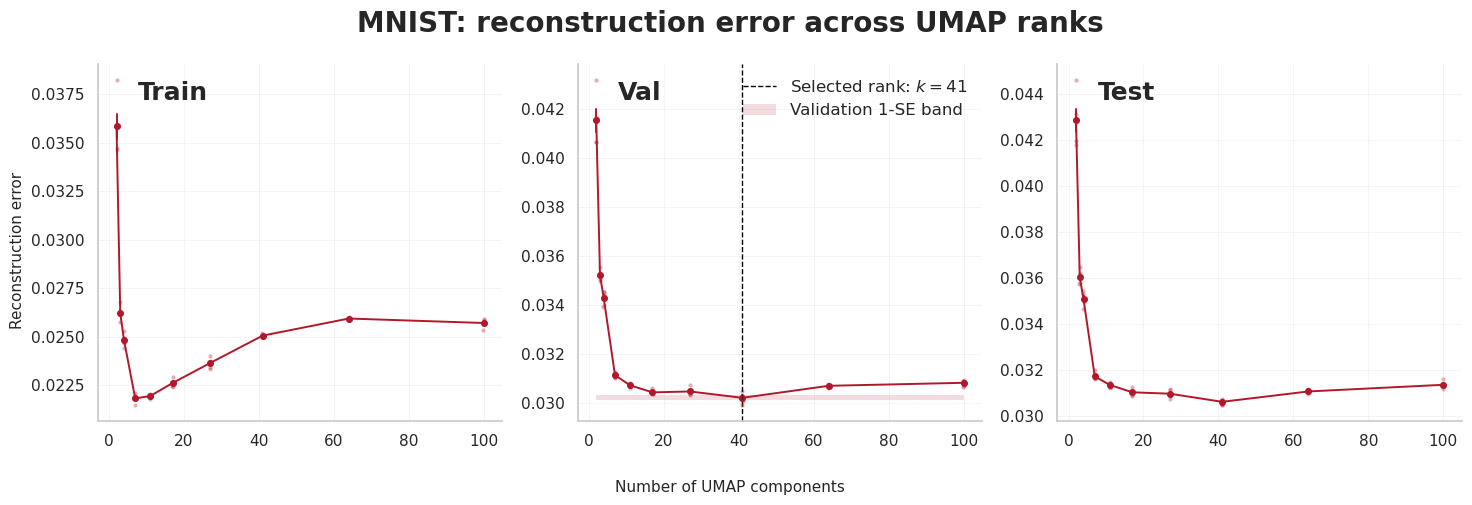

In [114]:
A = pd.DataFrame(mnist_umap_comp_res_dict).sort_values("n_components")
K = np.array(sorted(A.n_components.unique()))

S = (A[A.split.eq("Val")]
     .groupby("n_components")
     .agg(mean=("recon_loss", "mean"), sem=("recon_loss", "sem")))

best_k = S["mean"].idxmin()
lo, hi = S.loc[best_k, "mean"] - S.loc[best_k, "sem"], S.loc[best_k, "mean"] + S.loc[best_k, "sem"]
sel_k = S[(S["mean"].between(lo, hi))].index.min()

ranks = np.unique(np.logspace(np.log10(K.min()), np.log10(K.max()), 20).astype(int))

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=False)

colors = {"medal": "#B2182B", "pca": "#4D4D4D"}
Xs = {"Train": X, "Val": X_val, "Test": X_test}

for ax, (split, X_) in zip(axes, Xs.items()):
    sub = A[A.split.eq(split)]

    sns.stripplot(data=sub, x="n_components", y="recon_loss",
                  color=colors["medal"], size=3, alpha=.35, jitter=.1,
                  native_scale=True, ax=ax)

    sns.pointplot(data=sub, x="n_components", y="recon_loss",
                  errorbar="se", color=colors["medal"], markers="o",
                  markersize=4, linewidth=1.4, native_scale=True, ax=ax)

    if split == "Val": ax.axvline(sel_k, c="black", ls="--", lw=1)
    ax.text(.1, .9, split, transform=ax.transAxes, weight="bold", fontsize=18)

    ax.set(xlabel="", ylabel="")
    ax.grid(alpha=.25, lw=.6)
    ax.spines[["top", "right"]].set_visible(False)

axes[1].fill_between(K, lo, hi, color=colors["medal"], alpha=.15, lw=0)

legend_handles = [
    Line2D([0], [0], color="black", ls="--", lw=1,
           label=f"Selected rank: $k={sel_k}$"),
    Patch(facecolor=colors["medal"], alpha=.15, edgecolor="none",
          label="Validation 1-SE band"),
]

axes[1].legend(handles=legend_handles, frameon=False, fontsize=12, loc="upper right")

fig.supxlabel("Number of UMAP components", fontsize=11)
fig.supylabel("Reconstruction error", fontsize=11)
fig.suptitle("MNIST: reconstruction error across UMAP ranks", weight="bold", fontsize=20)

plt.tight_layout()
plt.show()

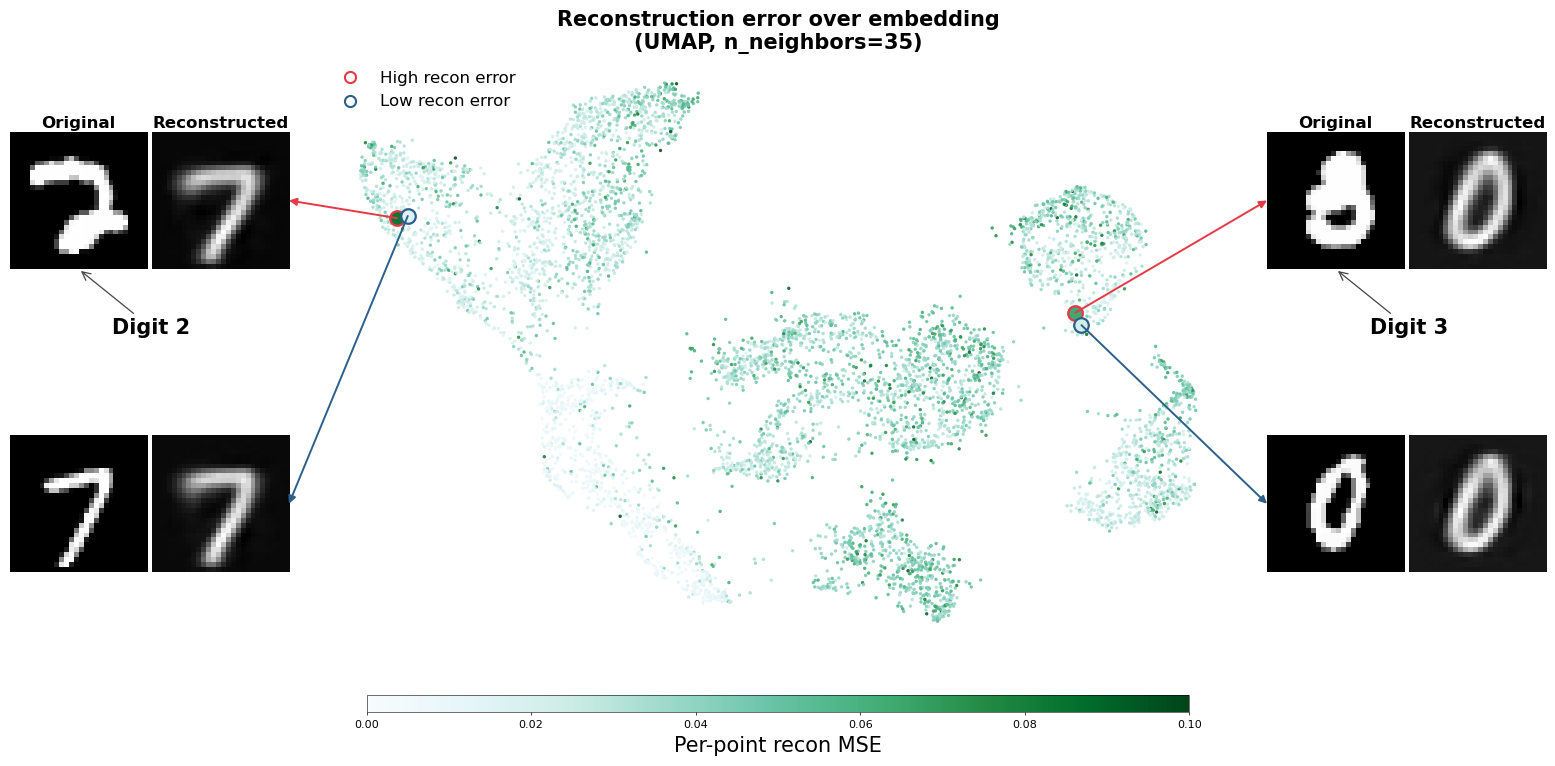

In [65]:
plt.rcParams.update({
    'font.family':     'sans-serif',
    'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':       10,
    'pdf.fonttype':    42,
    'ps.fonttype':     42,
})

# ─── INDICES ───────────────────────────────────────────────────────────────────
left_high_idx  = 1501  # digit 2 – high error, now on LEFT
left_low_idx   = 4880  # digit 7 – low error,  now on LEFT
right_high_idx = 411   # digit 8 – high error, now on RIGHT
right_low_idx  = 2830  # digit 0 – low error,  now on RIGHT

embed     = student_embed_umap01.detach().cpu().numpy()
recon_err = np.array(per_sample_recon_umap01)
cmap_bg   = sns.color_palette("BuGn", as_cmap=True)
norm_bg   = mcolors.Normalize(vmin=0, vmax=0.1)

def norm_img(a):
    mn, mx = a.min(), a.max()
    return (a - mn) / (mx - mn + 1e-8)

def get_orig(idx):
    return norm_img(np.asarray(X)[idx].reshape(28, 28))

def get_recon(idx):
    return norm_img(student_recon_umap01.detach().cpu().numpy()[idx].reshape(28, 28))

fig = plt.figure(figsize=(16, 8))

gs = gridspec.GridSpec(
    1, 3, figure=fig,
    left=0.02, right=0.98, top=0.87, bottom=0.13,
    width_ratios=[0.85, 2.8, 0.85],
    wspace=0.06,
)

ax_umap = fig.add_subplot(gs[1])

gs_L = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[0], hspace=0.05, wspace=0.03)
gs_R = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[2], hspace=0.05, wspace=0.03)
iL   = [[fig.add_subplot(gs_L[r, c]) for c in range(2)] for r in range(2)]
iR   = [[fig.add_subplot(gs_R[r, c]) for c in range(2)] for r in range(2)]

ax_umap.scatter(embed[:, 0], embed[:, 1],
                c=recon_err, cmap=cmap_bg, norm=norm_bg,
                s=6, alpha=0.85, linewidths=0, rasterized=True)

for idx, ec in [(left_high_idx,  '#E63946'), (right_high_idx, '#E63946'),
                (left_low_idx,   '#2C5F8A'), (right_low_idx,  '#2C5F8A')]:
    ax_umap.scatter(embed[idx, 0], embed[idx, 1],
                    c=[recon_err[idx]], cmap=cmap_bg, norm=norm_bg,
                    s=110, linewidths=1.6, edgecolors=ec, zorder=5)

ax_umap.axis('off')
ax_umap.set_title(
    'Reconstruction error over embedding\n(UMAP, n_neighbors=35)',
    fontsize=15, fontweight='bold', pad=5,
)
ax_umap.legend(
    handles=[
        Line2D([0],[0], marker='o', color='w', markeredgecolor='#E63946',
               markeredgewidth=1.5, markersize=8, label='High recon error'),
        Line2D([0],[0], marker='o', color='w', markeredgecolor='#2C5F8A',
               markeredgewidth=1.5, markersize=8, label='Low recon error'),
    ],
    loc='upper left', frameon=False, fontsize=12,
)

for (grid, hi, lo) in [(iL, left_high_idx, left_low_idx),
                        (iR, right_high_idx, right_low_idx)]:
    grid[0][0].imshow(get_orig(hi),  cmap='gray', vmin=0, vmax=1)
    grid[0][1].imshow(get_recon(hi), cmap='gray', vmin=0, vmax=1)
    grid[1][0].imshow(get_orig(lo),  cmap='gray', vmin=0, vmax=1)
    grid[1][1].imshow(get_recon(lo), cmap='gray', vmin=0, vmax=1)
    for row in grid:
        for ax in row:
            ax.axis('off')

for grid, hi_idx in [(iL, left_high_idx), (iR, right_high_idx)]:
    grid[0][0].set_title('Original',      fontsize=12, fontweight='bold', pad=3)
    grid[0][1].set_title('Reconstructed', fontsize=12, fontweight='bold', pad=3)
    grid[0][0].annotate(
        f'Digit {y[hi_idx]}',
        xy=(0.5, 0),        
        xycoords='axes fraction',
        xytext=(1.03, -0.5),    
        textcoords='axes fraction',
        ha='center', va='bottom',
        fontsize=15, fontweight='bold',
        annotation_clip=False,
        arrowprops=dict(arrowstyle='->', color='#444444', lw=0.9,
                        connectionstyle='arc3,rad=0.0'),
    )
for grid in [iL, iR]:
    for c in range(2):
        for sp in grid[0][c].spines.values():
            sp.set_visible(True)
            sp.set_edgecolor('#E63946')
            sp.set_linewidth(1.3)

def connect(pt_idx, ax_img, x_img_frac, color):
    """Arrow from UMAP data point to the near edge of an image axis."""
    fig.add_artist(ConnectionPatch(
        xyA=(embed[pt_idx, 0], embed[pt_idx, 1]),
        xyB=(x_img_frac, 0.5),
        coordsA='data',    coordsB='axes fraction',
        axesA=ax_umap,     axesB=ax_img,
        arrowstyle='-|>',
        color=color,
        linewidth=1.4,
        mutation_scale=11,
        zorder=10,
    ))

connect(left_high_idx, iL[0][1], 1.0, '#E63946')
connect(left_low_idx,  iL[1][1], 1.0, '#2C5F8A')
connect(right_high_idx, iR[0][0], 0.0, '#E63946')
connect(right_low_idx,  iR[1][0], 0.0, '#2C5F8A')

fig.canvas.draw()
pos = ax_umap.get_position()
cbar_ax = fig.add_axes([pos.x0 + 0.03, 0.05, pos.width - 0.06, 0.022])
cb = fig.colorbar(
    plt.cm.ScalarMappable(cmap=cmap_bg, norm=norm_bg),
    cax=cbar_ax, orientation='horizontal',
)
cb.set_label('Per-point recon MSE', fontsize=15)
cb.ax.tick_params(labelsize=8, width=0.5, length=2.5)
cb.outline.set_linewidth(0.4)


plt.show()

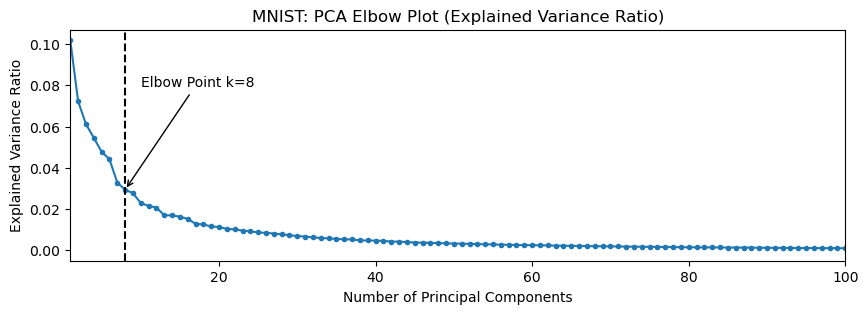

In [54]:
path = Path(PATH_PREFIX) / "MEDAL/comparisons/data/mnist_train.csv"
df = pd.read_csv(path)
cols_to_drop = ["labels"]
X = df.drop(columns=cols_to_drop)
X = X.select_dtypes(include=["number"])
pca = PCA()
pca.fit(X)

explained_var = pca.explained_variance_ratio_

# Elbow plot: explained variance ratio
plt.figure(figsize=(10, 3))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o', markersize=3)
plt.xlabel("Number of Principal Components")
plt.xlim(1, 100)
plt.ylabel("Explained Variance Ratio")
plt.axvline(x=8, ls='--', c='black')
# annotate the elbow point
plt.annotate('Elbow Point k=8', xy=(8, explained_var[7]), xytext =(10, explained_var[7]+0.05),
             arrowprops=dict(facecolor='black', arrowstyle='->'),)
plt.title("MNIST: PCA Elbow Plot (Explained Variance Ratio)")
plt.show()
